# CityFlowV2 multi-camera vehicle tracking + ReID — v2

v1 scored IDF1 36.4 on S02. v2 keeps the pipeline and changes the parts that
limited the score:

| | v1 | v2 |
|---|---|---|
| ReID training data | 295 real vehicles | + 1,362 synthetic vehicles (VehicleX, the challenge's simulation set); BatchNorm statistics re-estimated on real images afterwards |
| ReID input, GPUs | 256 px, one GPU | 320 px, both T4s |
| crops per tracklet | 6 | 10 |
| YOLO NMS IoU | 0.5 | 0.6, so cars queued behind each other are kept |
| tracking | one camera at a time | one camera per GPU at a time |
| gaps in a vehicle's track | left empty | filled by linear interpolation |
| camera bias in ReID features | kept | per-camera mean removed (on or off, tuned) |
| matching threshold, time weight, box filter | fixed by hand (the sweep was still rising) | tuned on the ground truth |
| scenes per run | one | several: S02 is scored and used for tuning, S06 (the test scene) gets a submission file |

Tuning on S02's own ground truth makes its score optimistic, so every run prints
three numbers: default settings, tuned settings, and a 2-fold estimate (settings
tuned on one half of the video, scored on the other half). The number that compares
with the leaderboard is `track1_S06.txt` scored by the challenge's evaluation server.

**Kaggle:** Accelerator **GPU T4 ×2**, Internet on, Run All. Expect about 1.5 h
(ReID training ≈ 50 min on two T4s). Set `QUICK = True` first for a short run that
checks everything works end to end (its scores are meaningless).

## 0. Setup

In [1]:
import subprocess
import sys


def pip_install(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)


try:
    import ultralytics  # noqa: F401
except ImportError:
    pip_install("ultralytics")
try:
    import lap  # noqa: F401  (ByteTrack; installed now so the parallel workers don't both install it)
except ImportError:
    pip_install("lap")
subprocess.run("nvidia-smi --query-gpu=name,memory.total --format=csv", shell=True)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 14.3 MB/s eta 0:00:00
name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB


CompletedProcess(args='nvidia-smi --query-gpu=name,memory.total --format=csv', returncode=0)

## Configuration

In [2]:
from pathlib import Path

SCENES = ["S02", "S06"]   # S01, S03, S04 (train) and S02, S05 (validation) have ground truth: they are
                          # scored and used to tune the matching. S06 (test) only gets a submission file.

ON_KAGGLE = Path("/kaggle/working").exists()
WORK = Path("/kaggle/working") if ON_KAGGLE else Path("cityflow_work")
SCRATCH = Path("/kaggle/tmp") if ON_KAGGLE else WORK / "data"   # downloads (not saved with the output)

CITYFLOW_URL = ("https://drive.usercontent.google.com/download?"
                "id=13wNJpS_Oaoe-7y5Dzexg_Ol7bKu1OWuC&export=download&confirm=t")
REID_URL = ("https://drive.usercontent.google.com/download?"
            "id=18LJ92tGKMThsHJI0BIxZCo8VUytsXWTc&export=download&confirm=t")
SYN_URL = ("https://drive.usercontent.google.com/download?"
           "id=11LetqbcckLD4IofrAvk07LM95cyEnnlN&export=download&confirm=t")
REID_DATA = None          # optional: AICity21_Track2_ReID.zip or its extracted folder
SYN_DATA = None           # optional: AICity21_Track2_ReID_Simulation.zip or its extracted folder

# ---- single-camera tracking ----
DETECTOR = "yolo11x.pt"   # downloaded automatically
IMGSZ = 1280
DET_CONF = 0.1
NMS_IOU = 0.6             # v1: 0.5; higher keeps overlapping vehicles in queues
TRACK_BUFFER = 30         # frames (3 s at 10 FPS) a lost track is kept alive
PARALLEL_TRACKING = True  # one camera per GPU at a time when there are 2+ GPUs
MAX_FRAMES = None         # e.g. 300 for a quick dry run

# ---- ReID ----
REID_WEIGHTS = None       # .pth saved by an earlier run -> skips training
REID_BACKBONE = "resnet50_ibn_a"   # falls back to torchvision "resnet50" if IBN-Net can't be loaded
REID_SIZE = 320
REID_EPOCHS = 12
REID_P, REID_K = 16, 4    # identities x images per batch
USE_SYNTHETIC = True      # add the VehicleX simulation set (2.3 GB download)
SYN_SHARE = 0.5           # share of the identities in each batch taken from the synthetic set
BN_ADAPT_BATCHES = 100    # re-estimate BatchNorm statistics on real images after training (0 = off)
MULTI_GPU = True          # train on all GPUs (DataParallel)
REID_MAX_ITERS = None     # cap on iterations per epoch (debugging)
AMP = True                # fp16; set False on GPUs without tensor cores (GTX 10xx / 16xx)

# ---- tracklets ----
MIN_TRACK_FRAMES = 5
MIN_BOX_AREA = 1500       # px^2
MIN_ROI_DETS = 3          # a tracklet needs this many boxes fully inside roi.jpg
CROPS_PER_TRACK = 10      # v1: 6
STITCH_MAX_GAP = 4.0      # s
STITCH_MIN_SIM = 0.5
STATIC_MAX_MOVE = 0.3     # tracklets moving less than this x box height are parked cars

# ---- cross-camera association (defaults; replaced by the tuned values) ----
MAX_GAP = 240.0           # s between two sightings of one vehicle
ZONES_PER_CAM = 6
CONFIDENT_SIM = 0.6       # mutual-best pairs above this similarity teach the camera links
LINK_MIN_N = 3
LINK_MIN_SIGMA = 3.0      # s
UNSEEN_LINK = 0.75        # time term for camera/zone pairs without a learned link (0..1)
W_TIME = 0.3
W_LOC = 0.2
LOC_D0, LOC_SCALE, LOC_DT = 8.0, 25.0, 0.5   # m, m, s
ACCEPT = 0.75             # clusters merge while their average pair cost is below this
CAM_DEBIAS = False        # subtract each camera's mean ReID feature before matching
RECIPROCAL_K = 2          # a link must be among the K cheapest for both tracklets (per camera pair)
CALIB_ROUNDS = 2          # cluster -> re-learn camera links -> cluster again

# ---- output ----
MIN_OUT_BOX_H = 50        # px; smaller boxes are left out (the GT rarely labels far-away vehicles)
INTERP_MAX_GAP = 20       # fill gaps of up to this many frames in a vehicle's track in one camera

# ---- tuning on the scenes that have ground truth ----
TUNE = True
TUNE_ACCEPT = [round(0.45 + 0.05 * i, 2) for i in range(14)]     # 0.45 ... 1.10
TUNE_W_TIME = [0.3, 0.6]
TUNE_DEBIAS = [False, True]
TUNE_MIN_H = [40, 50, 60, 70]
TUNE_INTERP = [0, 10, 20, 40]
TUNED_PARAMS = None       # tuned_params.json of an earlier run, used when no scene has ground truth

# ---- pictures and video ----
N_REVIEW = 40
DEMO_SCENE = None         # scene of the demo clip (default: the first one)
DEMO_SECONDS, DEMO_CAMS, DEMO_TRAIL, DEMO_ROWS = 20, 4, 2.0, 6

QUICK = False             # True: tiny settings to check the notebook runs end to end
if QUICK:
    REID_EPOCHS, REID_MAX_ITERS, BN_ADAPT_BATCHES, MAX_FRAMES = 1, 30, 5, 300
    TUNE_ACCEPT, TUNE_MIN_H, TUNE_INTERP = [0.6, 0.8], [50], [0, 20]

In [3]:
import glob
import io
import json
import math
import os
import random
import re
import shutil
import struct
import time
import urllib.request
import warnings
import zipfile
import zlib
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass, field
from itertools import product
from typing import Dict, List, Optional

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from PIL import Image
from scipy.optimize import linear_sum_assignment

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_GPUS = torch.cuda.device_count()
torch.set_num_threads(os.cpu_count() or 1)     # importing ultralytics sets OMP_NUM_THREADS=1
torch.backends.cudnn.benchmark = True
USE_FP16 = DEVICE == "cuda" and AMP
warnings.filterwarnings("ignore", message=r"Detected call of `lr_scheduler\.step\(\)` before")
SPLIT = {"S01": "train", "S03": "train", "S04": "train",
         "S02": "validation", "S05": "validation", "S06": "test"}
FPS_OVERRIDE = {"c015": 8.0}          # ReadMe: every video is 10 FPS except c015
for d in (WORK, SCRATCH):
    d.mkdir(parents=True, exist_ok=True)
    print(f"{d}: {shutil.disk_usage(d).free / 1e9:.0f} GB free")
print(f"device: {DEVICE}, GPUs: {N_GPUS}")

/kaggle/working: 21 GB free
/kaggle/tmp: 1149 GB free
device: cuda, GPUs: 2


## 1. Data
An attached Kaggle dataset that contains `<split>/<scene>/c*/vdo.avi` is used as is.
Otherwise only the files of each scene are pulled out of the official zip on Google
Drive with HTTP range requests (segmentation masks are skipped).

In [4]:
DRIVE_REFUSED = ("Google Drive did not serve the file (download quota, or the link changed). "
                 "Wait a few hours, or download it yourself and attach it as a Kaggle dataset.")


class HttpRangeFile(io.RawIOBase):
    """Seekable read-only view of a remote file (enough for zipfile's directory)."""

    def __init__(self, url):
        self.url, self.pos = url, 0
        req = urllib.request.Request(url, headers={"Range": "bytes=0-0"})
        with urllib.request.urlopen(req) as r:
            if "Content-Range" not in r.headers:
                raise RuntimeError(DRIVE_REFUSED)
            self.size = int(r.headers["Content-Range"].split("/")[1])

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self.pos

    def seek(self, off, whence=0):
        self.pos = {0: off, 1: self.pos + off, 2: self.size + off}[whence]
        return self.pos

    def readinto(self, b):
        n = min(len(b), self.size - self.pos)
        if n <= 0:
            return 0
        req = urllib.request.Request(self.url, headers={"Range": f"bytes={self.pos}-{self.pos + n - 1}"})
        with urllib.request.urlopen(req) as r:
            data = r.read()
        b[:len(data)] = data
        self.pos += len(data)
        return len(data)


def open_remote_zip(url):
    return zipfile.ZipFile(io.BufferedReader(HttpRangeFile(url), buffer_size=1 << 20))


def download_member(url, zi, dest: Path, retries=3):
    """Stream one zip member with a single range request; checks size and CRC."""
    dest.parent.mkdir(parents=True, exist_ok=True)
    for attempt in range(retries):
        try:
            req = urllib.request.Request(url, headers={
                "Range": f"bytes={zi.header_offset}-{zi.header_offset + 29}"})
            with urllib.request.urlopen(req) as r:
                hdr = r.read()
            n_name, n_extra = struct.unpack("<HH", hdr[26:30])
            start = zi.header_offset + 30 + n_name + n_extra
            req = urllib.request.Request(url, headers={
                "Range": f"bytes={start}-{start + zi.compress_size - 1}"})
            dec = (zlib.decompressobj(-zlib.MAX_WBITS)
                   if zi.compress_type == zipfile.ZIP_DEFLATED else None)
            crc, size = 0, 0
            tmp = dest.with_name(dest.name + ".part")
            with urllib.request.urlopen(req) as r, open(tmp, "wb") as f:
                while True:
                    chunk = r.read(1 << 22)
                    if not chunk:
                        break
                    if dec is not None:
                        chunk = dec.decompress(chunk)
                    f.write(chunk)
                    crc, size = zlib.crc32(chunk, crc), size + len(chunk)
                if dec is not None:
                    tail = dec.flush()
                    f.write(tail)
                    crc, size = zlib.crc32(tail, crc), size + len(tail)
            if size != zi.file_size or crc != zi.CRC:
                raise IOError("size/CRC mismatch")
            tmp.rename(dest)
            return
        except Exception as e:
            if attempt == retries - 1:
                raise
            print(f"  retry {zi.filename}: {e}")
            time.sleep(5)


def download_file(url, dest: Path):
    tmp = dest.with_name(dest.name + ".part")
    with urllib.request.urlopen(url) as r, open(tmp, "wb") as f:
        if "text/html" in r.headers.get("Content-Type", ""):
            raise RuntimeError(DRIVE_REFUSED)
        total, got, t0 = int(r.headers.get("Content-Length", 0)), 0, time.time()
        while True:
            chunk = r.read(1 << 22)
            if not chunk:
                break
            f.write(chunk)
            got += len(chunk)
            if got % (1 << 28) < (1 << 22):
                print(f"  {got / 1e9:.2f}/{total / 1e9:.2f} GB ({got / 1e6 / (time.time() - t0):.0f} MB/s)")
    tmp.rename(dest)


def find_attached(scene):
    if not Path("/kaggle/input").exists():
        return None
    for p in glob.glob(f"/kaggle/input/**/{SPLIT[scene]}/{scene}", recursive=True):
        if glob.glob(f"{p}/c*/vdo.avi"):
            return Path(p).parents[1]
    return None


def fetch_scene(scene, root: Path):
    done = root / f".{scene}_complete"
    if done.exists():
        return root
    print(f"fetching {scene} from the CityFlowV2 zip ...")
    z = open_remote_zip(CITYFLOW_URL)
    want = [zi for zi in z.infolist() if not zi.is_dir() and (
        (zi.filename.startswith(f"{SPLIT[scene]}/{scene}/") and "/segm/" not in zi.filename)
        or zi.filename == f"cam_timestamp/{scene}.txt")]
    total = sum(zi.file_size for zi in want)
    print(f"  {len(want)} files, {total / 1e9:.2f} GB")
    t0 = time.time()

    def get(zi):
        out = root / zi.filename
        if not (out.exists() and out.stat().st_size == zi.file_size):
            download_member(CITYFLOW_URL, zi, out)

    with ThreadPoolExecutor(8) as ex:
        list(ex.map(get, want))
    print(f"  done in {time.time() - t0:.0f} s")
    done.touch()
    return root

### Scenes: cameras, time base, ROI, ground-plane calibration, ground truth
`calibration.txt` holds a GPS→image homography (plus intrinsics and distortion for
the fisheye cameras); its inverse gives the ground position of a box's bottom-centre.
The calibration is rough, so position is only a soft cue.

In [5]:
@dataclass
class Camera:
    name: str
    idx: int
    video: Path
    fps: float
    W: int
    H: int
    n_frames: int
    offset: float
    roi: np.ndarray
    Hinv: np.ndarray
    K: Optional[np.ndarray]
    D: Optional[np.ndarray]
    ref: tuple = None              # lat0, lon0, m per degree lat, m per degree lon (shared by the scene)
    gc: np.ndarray = None          # ground position of the view centre (m)


@dataclass
class Scene:
    name: str
    dir: Path
    cams: Dict[str, Camera]
    gt: Optional[np.ndarray]       # camera, id, frame, x, y, w, h
    out: Path
    t_mid: float
    raw: dict = None               # camera -> single-camera tracks
    all: list = None               # every tracklet
    used: list = None              # tracklets that take part in the matching
    assoc: dict = field(default_factory=dict)
    loc_cache: dict = field(default_factory=dict)
    gids: dict = field(default_factory=dict)     # final {index in used: global id}

    def half(self, arr):
        """0 / 1: whether each row [camera, id, frame, ...] is in the first or second half of the video."""
        t = np.zeros(len(arr))
        for c in self.cams.values():
            m = arr[:, 0] == c.idx
            t[m] = c.offset + (arr[m, 2] - 1) / c.fps
        return (t >= self.t_mid).astype(int)


def read_calibration(path: Path):
    txt = path.read_text()

    def mat(key):
        m = re.search(key + r":\s*([^\n]+)", txt)
        if not m:
            return None
        return np.array([[float(v) for v in row.split()] for row in m.group(1).strip().split(";")])

    return mat("Homography matrix"), mat("Intrinsic parameter matrix"), mat("Distortion coefficients")


def to_latlon(cam: Camera, u, v):
    pts = np.stack([np.atleast_1d(u), np.atleast_1d(v)], 1).astype(np.float64)
    if cam.K is not None:
        pts = cv2.undistortPoints(pts.reshape(-1, 1, 2), cam.K, cam.D, P=cam.K).reshape(-1, 2)
    q = np.c_[pts, np.ones(len(pts))] @ cam.Hinv.T
    return q[:, 0] / q[:, 2], q[:, 1] / q[:, 2]


def to_world(cam: Camera, u, v):
    lat0, lon0, m_lat, m_lon = cam.ref
    lat, lon = to_latlon(cam, u, v)
    x, y = (lon - lon0) * m_lon, (lat - lat0) * m_lat
    if cam.gc is not None:
        bad = ~np.isfinite(x) | (np.hypot(x - cam.gc[0], y - cam.gc[1]) > 300)
        x[bad], y[bad] = np.nan, np.nan
    return x, y


def roi_centre(cam):
    ys, xs = np.nonzero(cam.roi)
    return float(np.median(xs)), float(np.percentile(ys, 75))


def load_gt(sdir: Path, cams: Dict[str, Camera]):
    rows = []
    for c in cams.values():
        f = sdir / c.name / "gt" / "gt.txt"
        if f.exists():
            a = np.loadtxt(f, delimiter=",", ndmin=2)
            rows.append(np.c_[np.full(len(a), c.idx), a[:, 1], a[:, 0], a[:, 2:6]])
    return np.vstack(rows).round().astype(np.int64) if rows else None


def load_scene(name) -> Scene:
    data = find_attached(name) or fetch_scene(name, SCRATCH / "cityflow")
    sdir = data / SPLIT[name] / name
    ts = data / "cam_timestamp" / f"{name}.txt"
    offsets = ({c: float(o) for c, o in (l.split() for l in ts.read_text().splitlines() if l.strip())}
               if ts.exists() else {})
    if not offsets:
        print(f"WARNING: no cam_timestamp file for {name}, assuming all cameras start together")
    cams = {}
    for d in sorted(sdir.glob("c*")):
        if not (d / "vdo.avi").exists():
            continue
        cap = cv2.VideoCapture(str(d / "vdo.avi"))
        W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        cap.release()
        Hm, K, D = read_calibration(d / "calibration.txt")
        roi = cv2.imread(str(d / "roi.jpg"), cv2.IMREAD_GRAYSCALE)
        cams[d.name] = Camera(d.name, int(d.name[1:]), d / "vdo.avi", FPS_OVERRIDE.get(d.name, 10.0),
                              W, H, n, offsets.get(d.name, 0.0), roi > 127, np.linalg.inv(Hm),
                              K, None if D is None else D.reshape(-1))
    ll = np.array([np.r_[to_latlon(c, *roi_centre(c))] for c in cams.values()])
    lat0, lon0 = ll.mean(0)
    ref = (lat0, lon0, 110540.0, 111320.0 * math.cos(math.radians(lat0)))
    for c in cams.values():
        c.ref = ref
        c.gc = np.r_[to_world(c, *roi_centre(c))]
        print(f"  {name}/{c.name}: {c.W}x{c.H}, {c.n_frames} frames @ {c.fps:g} fps, offset {c.offset:7.3f} s"
              f"{', fisheye' if c.K is not None else ''}")
    gt = load_gt(sdir, cams)
    out = WORK / f"out_{name}"
    out.mkdir(parents=True, exist_ok=True)
    t_mid = 0.5 * (min(c.offset for c in cams.values()) +
                   max(c.offset + c.n_frames / c.fps for c in cams.values()))
    print(f"{name}: {len(cams)} cameras, " + (f"ground truth: {len(set(gt[:, 1].tolist()))} vehicles, "
                                             f"{len(gt)} boxes" if gt is not None else "no ground truth"))
    return Scene(name, sdir, cams, gt, out, t_mid)


SC = {name: load_scene(name) for name in SCENES}
GT_SCENES = [sc for sc in SC.values() if sc.gt is not None]
EXCLUDE_IDS = set()                  # vehicles of the scored scenes: kept out of ReID training
for sc in GT_SCENES:
    EXCLUDE_IDS |= set(sc.gt[:, 1].tolist())

fetching S02 from the CityFlowV2 zip ...
  65 files, 1.08 GB
  done in 14 s
  S02/c006: 1920x1080, 2110 frames @ 10 fps, offset   0.000 s
  S02/c007: 1920x1080, 1965 frames @ 10 fps, offset   0.061 s
  S02/c008: 1920x1080, 1924 frames @ 10 fps, offset   0.421 s
  S02/c009: 1920x1080, 2110 frames @ 10 fps, offset   0.660 s
S02: 4 cameras, ground truth: 145 vehicles, 20956 boxes
fetching S06 from the CityFlowV2 zip ...
  31 files, 0.67 GB
  done in 8 s
  S06/c041: 1280x960, 2001 frames @ 10 fps, offset   0.000 s, fisheye
  S06/c042: 1280x960, 2001 frames @ 10 fps, offset   0.000 s, fisheye
  S06/c043: 1280x960, 2001 frames @ 10 fps, offset   0.000 s
  S06/c044: 1280x960, 2001 frames @ 10 fps, offset   0.000 s, fisheye
  S06/c045: 1280x720, 2001 frames @ 10 fps, offset   0.000 s
  S06/c046: 1280x720, 2001 frames @ 10 fps, offset   0.000 s
S06: 6 cameras, no ground truth


## 2. Vehicle ReID model
ResNet50-IBN-a, last stride 1, GeM pooling, BNNeck; label-smoothed cross-entropy +
batch-hard triplet loss. Each batch takes half of its identities from the real
CityFlowV2-ReID set and half from the synthetic VehicleX set; afterwards the
BatchNorm statistics are re-estimated on real images only. The vehicles of the scored
scenes are left out of training and used to measure cross-camera retrieval.

In [6]:
REID_ROOT, SYN_ROOT = "AIC21_Track2_ReID", "AIC21_Track2_ReID_Simulation"
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
TEST_TF = T.Compose([T.Resize((REID_SIZE, REID_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])
TRAIN_TF = T.Compose([T.Resize((REID_SIZE, REID_SIZE)), T.RandomHorizontalFlip(), T.Pad(10),
                      T.RandomCrop(REID_SIZE), T.ToTensor(), T.Normalize(MEAN, STD),
                      T.RandomErasing(p=0.5, value="random")])
NUM_WORKERS = min(8, os.cpu_count() or 2)


class ImageSource:
    """Images read from a zip or from an extracted folder."""

    def __init__(self, path: Path):
        self.path, self.is_zip = Path(path), str(path).endswith(".zip")
        self._z, self._pid = None, None

    def read_bytes(self, name):
        if not self.is_zip:
            return (self.path / name).read_bytes()
        if self._z is None or self._pid != os.getpid():      # one handle per worker
            self._z, self._pid = zipfile.ZipFile(self.path), os.getpid()
        return self._z.read(name)

    def read(self, name):
        img = cv2.imdecode(np.frombuffer(self.read_bytes(name), np.uint8), cv2.IMREAD_COLOR)
        return img if img is not None else np.zeros((64, 64, 3), np.uint8)

    def names(self):
        if self.is_zip:
            with zipfile.ZipFile(self.path) as z:
                return z.namelist()
        return [p.relative_to(self.path).as_posix() for p in self.path.rglob("*") if p.is_file()]


def find_source(zip_name, root, url, explicit=None) -> ImageSource:
    cands = ([explicit] if explicit else []) + glob.glob(f"/kaggle/input/**/{zip_name}", recursive=True) + [
        str(SCRATCH / zip_name)]
    for c in cands:
        p = Path(c)
        if p.is_file():
            return ImageSource(p)
        if (p / root / "train_label.xml").exists():
            return ImageSource(p)
        if p.name == root and (p / "train_label.xml").exists():
            return ImageSource(p.parent)
    for x in glob.glob(f"/kaggle/input/**/{root}/train_label.xml", recursive=True):
        return ImageSource(Path(x).parents[1])
    dest = SCRATCH / zip_name
    print(f"downloading {zip_name} ...")
    download_file(url, dest)
    return ImageSource(dest)


def parse_labels(xml):
    out = []
    for attrs in re.findall(r"<Item ([^>]*)/>", xml):
        a = dict(re.findall(r'(\w+)="([^"]*)"', attrs))
        cam = a.get("cameraID", "c0")[1:]
        out.append((a["imageName"], int(a["vehicleID"]), int(cam) if cam.isdigit() else 0))
    return out


def real_items(src):
    """[(image path, vehicle id, camera)] of the real ReID training split."""
    xml = src.read_bytes(f"{REID_ROOT}/train_label.xml").decode("gb2312", errors="ignore")
    return [(f"{REID_ROOT}/image_train/{n}", v, c) for n, v, c in parse_labels(xml)]


def syn_items(src):
    """Same for the synthetic set; image paths are looked up by file name."""
    xml = src.read_bytes(f"{SYN_ROOT}/train_label.xml").decode("utf-8", errors="ignore")
    where = {}
    for n in src.names():
        if n.lower().endswith(".jpg"):
            where.setdefault(n.rsplit("/", 1)[-1], n)
    return [(where[n], v, c) for n, v, c in parse_labels(xml) if n in where]


def to_pil(bgr):
    return Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))


class ReIDImages(torch.utils.data.Dataset):
    """items: (source index, image path, label)."""

    def __init__(self, srcs, items, tf):
        self.srcs, self.items, self.tf = srcs, items, tf

    def __len__(self):
        return len(self.items)

    def __getitem__(self, k):
        s, name, lab = self.items[k]
        return self.tf(to_pil(self.srcs[s].read(name))), lab


class PKSampler(torch.utils.data.Sampler):
    """K images of each of P identities per batch; the identities are drawn from the
    groups (real, synthetic) in fixed numbers."""

    def __init__(self, labels, groups, shares, K, n_batches):
        self.index = defaultdict(list)
        for i, lab in enumerate(labels):
            self.index[lab].append(i)
        self.groups, self.shares, self.K, self.n = groups, shares, K, n_batches

    def __len__(self):
        return self.n * sum(self.shares) * self.K

    def __iter__(self):
        for _ in range(self.n):
            for ids, p in zip(self.groups, self.shares):
                for pid in (random.sample(ids, p) if len(ids) >= p else random.choices(ids, k=p)):
                    idx = self.index[pid]
                    yield from (random.sample(idx, self.K) if len(idx) >= self.K
                                else random.choices(idx, k=self.K))


class GeM(nn.Module):
    def __init__(self, p=3.0, eps=1e-6):
        super().__init__()
        self.p, self.eps = nn.Parameter(torch.ones(1) * p), eps

    def forward(self, x):
        x = x.float().clamp(min=self.eps).pow(self.p)          # fp32: avoids fp16 overflow
        return F.avg_pool2d(x, x.shape[-2:]).pow(1.0 / self.p)


IBN_URL = "https://github.com/XingangPan/IBN-Net/releases/download/v1.0/resnet50_ibn_a-d9d0bb7b.pth"


def load_backbone(name, pretrained=True):
    if name == "resnet50_ibn_a":
        try:
            m = torch.hub.load("XingangPan/IBN-Net", "resnet50_ibn_a", pretrained=False,
                               trust_repo=True, skip_validation=True, verbose=False)
            if pretrained:                   # the hub's own loader fails on CPU-only machines
                m.load_state_dict(torch.hub.load_state_dict_from_url(IBN_URL, map_location="cpu"))
            return m
        except Exception as e:
            print(f"  IBN-Net unavailable ({e}); using torchvision resnet50")
            name = "resnet50"
    weights = None
    if pretrained:
        weights = "IMAGENET1K_V2" if name in ("resnet50", "resnet101") else "IMAGENET1K_V1"
    return getattr(torchvision.models, name)(weights=weights)


class ReIDNet(nn.Module):
    def __init__(self, backbone, num_classes=0, pretrained=True):
        super().__init__()
        base = load_backbone(backbone, pretrained)
        for m in base.layer4[0].modules():          # last stride 1: finer final feature map
            if isinstance(m, nn.Conv2d) and m.stride == (2, 2):
                m.stride = (1, 1)
        self.dim = base.fc.in_features
        self.body = nn.Sequential(base.conv1, base.bn1, base.relu, base.maxpool,
                                  base.layer1, base.layer2, base.layer3, base.layer4)
        self.pool = GeM()
        self.neck = nn.BatchNorm1d(self.dim)
        self.neck.bias.requires_grad_(False)
        self.head = nn.Linear(self.dim, num_classes, bias=False) if num_classes else None

    def forward(self, x):
        f = self.pool(self.body(x)).flatten(1)
        if self.training:
            return f, self.head(self.neck(f))
        return F.normalize(self.neck(f), dim=1)


def triplet_hard(feat, labels, margin=0.3):
    d = torch.cdist(feat, feat)
    same = labels[:, None] == labels[None, :]
    hardest_pos = (d * same).max(1).values
    hardest_neg = d.masked_fill(same, float("inf")).min(1).values
    return F.relu(hardest_pos - hardest_neg + margin).mean()


def autocast():
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_FP16)


def train_reid(srcs, real, syn):
    """real / syn: [(image path, vehicle id, camera)] from srcs[0] / srcs[1]."""
    keys = sorted({(0, v) for _, v, _ in real}) + sorted({(1, v) for _, v, _ in syn})
    lab = {k: i for i, k in enumerate(keys)}
    items = [(0, n, lab[(0, v)]) for n, v, _ in real] + [(1, n, lab[(1, v)]) for n, v, _ in syn]
    groups = [[lab[k] for k in keys if k[0] == 0], [lab[k] for k in keys if k[0] == 1]]
    p_syn = int(round(REID_P * SYN_SHARE)) if syn else 0
    model = ReIDNet(REID_BACKBONE, len(keys)).to(DEVICE)
    net = nn.DataParallel(model) if MULTI_GPU and N_GPUS > 1 else model
    iters = len(real) // (REID_P * REID_K)
    if REID_MAX_ITERS:
        iters = min(iters, REID_MAX_ITERS)
    dl = torch.utils.data.DataLoader(
        ReIDImages(srcs, items, TRAIN_TF), batch_size=REID_P * REID_K,
        sampler=PKSampler([it[2] for it in items], groups, [REID_P - p_syn, p_syn], REID_K, iters),
        num_workers=NUM_WORKERS, pin_memory=DEVICE == "cuda", drop_last=True,
        persistent_workers=NUM_WORKERS > 0)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad],
                           lr=3.5e-4, weight_decay=5e-4)
    total, warm = REID_EPOCHS * iters, iters

    def lr_factor(it):              # 1 epoch linear warm-up, then cosine decay
        if it < warm:
            return 0.1 + 0.9 * it / warm
        return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * (it - warm) / max(1, total - warm)))

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_FP16)
    ce = nn.CrossEntropyLoss(label_smoothing=0.1)
    print(f"training ReID: {len(groups[0])} real + {len(groups[1])} synthetic vehicles, "
          f"{REID_P - p_syn} + {p_syn} identities per batch, {REID_SIZE} px, "
          f"{N_GPUS if net is not model else 1} GPU(s), {REID_EPOCHS} epochs x {iters} iterations")
    for ep in range(REID_EPOCHS):
        net.train()
        t0, n, s_loss, s_acc = time.time(), 0, 0.0, 0.0
        for x, y in dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with autocast():
                f, logits = net(x)
            loss = ce(logits.float(), y) + triplet_hard(f.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            n += 1
            s_loss += loss.item()
            s_acc += (logits.argmax(1) == y).float().mean().item()
        print(f"  epoch {ep + 1:2d}/{REID_EPOCHS}: loss {s_loss / n:.3f}, "
              f"train acc {s_acc / n:.2f}, {time.time() - t0:.0f} s")
    model.eval()
    return model, sorted({v for _, v, _ in real})


@torch.no_grad()
def adapt_bn(model, srcs, real, n_batches, bs=64):
    """Recompute every BatchNorm's running statistics on real images (the training
    batches were half synthetic)."""
    sample = random.Random(0).sample(real, min(len(real), n_batches * bs))
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            m.reset_running_stats()
            m.momentum = None                    # plain average over the batches below
    dl = torch.utils.data.DataLoader(ReIDImages(srcs, [(0, n, 0) for n, _, _ in sample], TEST_TF),
                                     batch_size=bs, num_workers=NUM_WORKERS, drop_last=True)
    model.train()
    for x, _ in dl:
        with autocast():
            model(x.to(DEVICE))
    model.eval()


@torch.no_grad()
def embed(model, crops, bs=128):
    """L2-normalised features of BGR crops (with flip averaging)."""
    out = []
    for i in range(0, len(crops), bs):
        x = torch.stack([TEST_TF(to_pil(c)) for c in crops[i:i + bs]]).to(DEVICE)
        with autocast():
            f = model(x) + model(torch.flip(x, dims=[3]))
        out.append(F.normalize(f.float(), dim=1).cpu())
    return torch.cat(out).numpy() if out else np.zeros((0, model.dim), np.float32)


@torch.no_grad()
def eval_reid(model, srcs, items, max_gallery=12000):
    """Cross-camera retrieval on held-out vehicles: one query per (vehicle, camera),
    gallery = their images from the other cameras."""
    rng = random.Random(0)
    by = defaultdict(list)
    for it in items:
        by[(it[1], it[2])].append(it)
    queries = [rng.choice(v) for v in by.values()]
    gallery = items if len(items) <= max_gallery else rng.sample(items, max_gallery)

    def feats(its):
        dl = torch.utils.data.DataLoader(ReIDImages(srcs, [(0, n, 0) for n, _, _ in its], TEST_TF),
                                         batch_size=128, num_workers=NUM_WORKERS)
        out = []
        for x, _ in dl:
            x = x.to(DEVICE)
            with autocast():
                f = model(x) + model(torch.flip(x, dims=[3]))
            out.append(F.normalize(f.float(), dim=1).cpu())
        return torch.cat(out).numpy()

    fq, fg = feats(queries), feats(gallery)
    gv, gc = np.array([g[1] for g in gallery]), np.array([g[2] for g in gallery])
    aps, r1 = [], []
    for k, (_, v, c) in enumerate(queries):
        keep = gc != c
        match = (gv[keep] == v)[np.argsort(-(fg[keep] @ fq[k]))]
        if not match.any():
            continue
        hits = np.cumsum(match)
        aps.append(float((hits[match] / (np.nonzero(match)[0] + 1)).mean()))
        r1.append(float(match[0]))
    print(f"ReID on the {len({v for _, v, _ in items})} held-out vehicles "
          f"({len(aps)} queries, {len(gallery)} gallery images): "
          f"mAP {np.mean(aps):.3f}, rank-1 {np.mean(r1):.3f}   (v1: mAP 0.490, rank-1 0.656)")


def load_reid(path):
    ck = torch.load(path, map_location="cpu")
    model = ReIDNet(ck["backbone"], 0, pretrained=False)
    model.load_state_dict(ck["state_dict"], strict=False)
    leak = EXCLUDE_IDS & set(ck.get("train_ids", []))
    if leak:
        print(f"WARNING: {len(leak)} vehicles of the scored scenes were in this model's training set; "
              f"scores will be optimistic")
    if ck.get("size", REID_SIZE) != REID_SIZE:
        print(f"WARNING: model trained at {ck['size']} px, REID_SIZE is {REID_SIZE}")
    print(f"loaded ReID weights {path}")
    return model.to(DEVICE).eval()


tag = "-".join(sc.name for sc in GT_SCENES) or "none"
ckpt = (Path(REID_WEIGHTS) if REID_WEIGHTS else WORK / (
    f"reid_{REID_BACKBONE}_{REID_SIZE}{'_syn' if USE_SYNTHETIC else ''}_excl{tag}{'_quick' if QUICK else ''}.pth"))
if ckpt.exists():
    REID = load_reid(ckpt)
else:
    srcs = [find_source("AICity21_Track2_ReID.zip", REID_ROOT, REID_URL, REID_DATA)]
    items = real_items(srcs[0])
    train_real = [it for it in items if it[1] not in EXCLUDE_IDS]
    held = [it for it in items if it[1] in EXCLUDE_IDS]
    syn = []
    if USE_SYNTHETIC:
        try:
            srcs.append(find_source("AICity21_Track2_ReID_Simulation.zip", SYN_ROOT, SYN_URL, SYN_DATA))
            syn = syn_items(srcs[1])
        except Exception as e:
            print(f"WARNING: synthetic set unavailable ({e}); training on real images only")
        if not syn:
            print("WARNING: no synthetic images found; training on real images only")
    print(f"ReID data: {len(train_real)} real images for training, {len(held)} images of "
          f"{len({v for _, v, _ in held})} scored vehicles held out, {len(syn)} synthetic images")
    REID, train_ids = train_reid(srcs, train_real, syn)
    if syn and BN_ADAPT_BATCHES:
        adapt_bn(REID, srcs, train_real, BN_ADAPT_BATCHES)
    sd = {k: v for k, v in REID.state_dict().items() if not k.startswith("head.")}
    torch.save({"backbone": REID_BACKBONE, "size": REID_SIZE, "state_dict": sd,
                "train_ids": train_ids, "scenes": tag}, ckpt)
    print(f"saved {ckpt}")
    if held:
        eval_reid(REID, srcs, held)
if DEVICE == "cuda":
    torch.cuda.empty_cache()

downloading AICity21_Track2_ReID.zip ...
  0.27/2.15 GB (78 MB/s)
  0.54/2.15 GB (89 MB/s)
  0.81/2.15 GB (97 MB/s)
  1.07/2.15 GB (98 MB/s)
  1.34/2.15 GB (101 MB/s)
  1.61/2.15 GB (105 MB/s)
  1.88/2.15 GB (108 MB/s)
  2.15/2.15 GB (109 MB/s)
downloading AICity21_Track2_ReID_Simulation.zip ...
  0.27/2.26 GB (108 MB/s)
  0.54/2.26 GB (115 MB/s)
  0.81/2.26 GB (121 MB/s)
  1.07/2.26 GB (118 MB/s)
  1.34/2.26 GB (118 MB/s)
  1.61/2.26 GB (115 MB/s)
  1.88/2.26 GB (113 MB/s)
  2.15/2.26 GB (112 MB/s)
ReID data: 44378 real images for training, 8339 images of 145 scored vehicles held out, 192150 synthetic images
Downloading: "https://github.com/XingangPan/IBN-Net/zipball/master" to /root/.cache/torch/hub/master.zip
Downloading: "https://github.com/XingangPan/IBN-Net/releases/download/v1.0/resnet50_ibn_a-d9d0bb7b.pth" to /root/.cache/torch/hub/checkpoints/resnet50_ibn_a-d9d0bb7b.pth


100%|██████████| 97.7M/97.7M [00:00<00:00, 151MB/s]


training ReID: 295 real + 1362 synthetic vehicles, 8 + 8 identities per batch, 320 px, 2 GPU(s), 12 epochs x 693 iterations
  epoch  1/12: loss 6.424, train acc 0.18, 1028 s
  epoch  2/12: loss 3.263, train acc 0.57, 1011 s
  epoch  3/12: loss 2.366, train acc 0.74, 1008 s
  epoch  4/12: loss 2.004, train acc 0.83, 1010 s
  epoch  5/12: loss 1.815, train acc 0.88, 1010 s
  epoch  6/12: loss 1.690, train acc 0.91, 1011 s
  epoch  7/12: loss 1.594, train acc 0.93, 1011 s
  epoch  8/12: loss 1.508, train acc 0.95, 1011 s
  epoch  9/12: loss 1.427, train acc 0.97, 1013 s
  epoch 10/12: loss 1.373, train acc 0.98, 1013 s
  epoch 11/12: loss 1.340, train acc 0.98, 1014 s
  epoch 12/12: loss 1.324, train acc 0.98, 1015 s
saved /kaggle/working/reid_resnet50_ibn_a_320_syn_exclS02.pth
ReID on the 145 held-out vehicles (450 queries, 8339 gallery images): mAP 0.427, rank-1 0.560   (v1: mAP 0.490, rank-1 0.656)


## 3. Single-camera tracking
YOLO (COCO car / bus / truck, class-agnostic NMS) + ByteTrack. With two GPUs each one
tracks a different camera at the same time (separate worker processes). Results are
cached as JSON, so a re-run skips this step.

In [7]:
TRACK_CODE = r'''
import json
import sys
import time
from collections import defaultdict
from pathlib import Path


def track_video(video, out_json, detector, imgsz, conf, iou, cfg_path, fp16, max_frames, classes, device):
    from ultralytics import YOLO
    from ultralytics.cfg import DEFAULT_CFG_DICT
    extra = {}
    if fp16:                       # newer ultralytics replaced half=True by quantize=16
        extra = {"quantize": 16} if "quantize" in DEFAULT_CFG_DICT else {"half": True}
    model = YOLO(detector)         # fresh model = fresh tracker state
    keep = [i for i, n in model.names.items() if n in classes]
    tracks, fidx, t0 = defaultdict(list), 0, time.time()
    for res in model.track(source=video, tracker=cfg_path, conf=conf, iou=iou, imgsz=imgsz,
                           classes=keep, agnostic_nms=True, persist=True, device=device,
                           stream=True, verbose=False, **extra):
        fidx += 1                  # frame numbers start at 1, as in gt.txt
        if max_frames and fidx > max_frames:
            break
        b = res.boxes
        if b is not None and b.id is not None:
            for tid, c, cf, xy in zip(b.id.int().tolist(), b.cls.int().tolist(),
                                      b.conf.tolist(), b.xyxy.tolist()):
                tracks[str(tid)].append(dict(frame=fidx, cls=res.names[c], conf=round(cf, 3),
                                             x1=round(xy[0], 1), y1=round(xy[1], 1),
                                             x2=round(xy[2], 1), y2=round(xy[3], 1)))
        if fidx % 500 == 0:
            print(f"{fidx} frames, {fidx / (time.time() - t0):.1f} fps", flush=True)
    tmp = Path(out_json + ".part")
    tmp.write_text(json.dumps({"frames": fidx, "tracks": tracks}))
    tmp.rename(out_json)
    return fidx, len(tracks)


if __name__ == "__main__":
    n, k = track_video(**json.loads(sys.argv[1]))
    print(f"{k} tracks, {n} frames", flush=True)
'''
_ns = {"__name__": "track_worker"}
exec(TRACK_CODE, _ns)
track_video = _ns["track_video"]
VEHICLE_NAMES = ["car", "bus", "truck"]


def tracker_yaml(path: Path) -> str:
    import yaml
    from ultralytics.utils.checks import check_yaml
    cfg = yaml.safe_load(Path(check_yaml("bytetrack.yaml")).read_text())
    cfg.update(track_high_thresh=0.35, track_low_thresh=0.1, new_track_thresh=0.4,
               track_buffer=TRACK_BUFFER, match_thresh=0.8, fuse_score=True)
    path.write_text(yaml.safe_dump(cfg))
    return str(path)


def track_scene(sc: Scene):
    tdir = sc.out / ("tracks_yolo" + (f"_{MAX_FRAMES}f" if MAX_FRAMES else ""))
    tdir.mkdir(parents=True, exist_ok=True)
    todo = [c for c in sc.cams.values() if not (tdir / f"{c.name}.json").exists()]
    if todo:
        cfg = tracker_yaml(tdir / "bytetrack.yaml")

        def args(c, device):
            return dict(video=str(c.video), out_json=str(tdir / f"{c.name}.json"), detector=DETECTOR,
                        imgsz=IMGSZ, conf=DET_CONF, iou=NMS_IOU, cfg_path=cfg, fp16=USE_FP16,
                        max_frames=MAX_FRAMES, classes=VEHICLE_NAMES, device=device)

        t0 = time.time()
        if PARALLEL_TRACKING and N_GPUS > 1:
            worker = WORK / "track_worker.py"
            worker.write_text(TRACK_CODE)
            queue, running = list(todo), {}
            while queue or running:
                for g in range(N_GPUS):
                    if queue and g not in [v[0] for v in running.values()]:
                        c = queue.pop(0)
                        log = open(tdir / f"{c.name}.log", "w")
                        p = subprocess.Popen([sys.executable, str(worker), json.dumps(args(c, 0))],
                                             stdout=log, stderr=subprocess.STDOUT, cwd=os.getcwd(),
                                             env=dict(os.environ, CUDA_VISIBLE_DEVICES=str(g)))
                        running[p] = (g, c, log, time.time())
                time.sleep(3)
                for p in [p for p in running if p.poll() is not None]:
                    g, c, log, ts = running.pop(p)
                    log.close()
                    lines = (tdir / f"{c.name}.log").read_text().strip().splitlines()
                    if p.returncode != 0 or not (tdir / f"{c.name}.json").exists():
                        for q in running:
                            q.kill()
                        raise RuntimeError(f"tracking {sc.name}/{c.name} failed:\n" + "\n".join(lines[-25:]))
                    print(f"  {sc.name}/{c.name} on GPU {g}: {lines[-1] if lines else ''} "
                          f"({time.time() - ts:.0f} s)")
        else:
            for c in todo:
                ts = time.time()
                n, k = track_video(**args(c, 0 if DEVICE == "cuda" else "cpu"))
                print(f"  {sc.name}/{c.name}: {k} tracks, {n} frames ({time.time() - ts:.0f} s)")
        print(f"{sc.name}: tracking took {time.time() - t0:.0f} s")
    sc.raw = {name: json.loads((tdir / f"{name}.json").read_text()) for name in sc.cams}


from ultralytics import YOLO
YOLO(DETECTOR)                 # download the weights once, before the workers start
for sc in SC.values():
    track_scene(sc)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
  S02/c007 on GPU 1: 135 tracks, 1965 frames (129 s)
  S02/c006 on GPU 0: 320 tracks, 2110 frames (144 s)
  S02/c008 on GPU 1: 219 tracks, 1924 frames (126 s)
  S02/c009 on GPU 0: 231 tracks, 2110 frames (141 s)
S02: tracking took 285 s
  S06/c042 on GPU 1: 313 tracks, 2001 frames (156 s)
  S06/c041 on GPU 0: 316 tracks, 2001 frames (159 s)
  S06/c043 on GPU 1: 252 tracks, 2001 frames (159 s)
  S06/c044 on GPU 0: 252 tracks, 2001 frames (156 s)
  S06/c045 on GPU 0: 197 tracks, 2001 frames (126 s)
  S06/c046 on GPU 1: 143 tracks, 2001 frames (126 s)
S06: tracking took 441 s


## 4. Tracklets, appearance, stitching
Per camera: drop tiny boxes and tracks outside the ROI, drop duplicate boxes on one
vehicle, merge ids that sit on the same vehicle at the same time; ReID features from
the clearest boxes of each tracklet; fragments of one vehicle stitched by
constant-velocity prediction plus ReID similarity; parked cars flagged; entry/exit
zones from k-means on where tracklets start and end.

In [8]:
@dataclass
class Tracklet:
    cam: str
    tid: str
    members: List[str]
    dets: List[dict]
    cls: str
    fps: float
    W: int
    H: int
    t: Optional[np.ndarray] = None      # global time of each box (s)
    wx: Optional[np.ndarray] = None     # ground position of each box (m, NaN if unknown)
    wy: Optional[np.ndarray] = None
    feat: Optional[np.ndarray] = field(default=None, repr=False)
    n_feat: int = 0
    crop: Optional[np.ndarray] = field(default=None, repr=False)
    zin: int = 0
    zout: int = 0
    static: bool = False
    gid: int = 0

    @property
    def t0(self):
        return float(self.t[0])

    @property
    def t1(self):
        return float(self.t[-1])

    def arrays(self):
        t = np.array([d["frame"] for d in self.dets], float) / self.fps
        x1 = np.array([d["x1"] for d in self.dets]) / self.W
        x2 = np.array([d["x2"] for d in self.dets]) / self.W
        y1 = np.array([d["y1"] for d in self.dets]) / self.H
        y2 = np.array([d["y2"] for d in self.dets]) / self.H
        return t, x1, y1, x2, y2


def majority_class(dets):
    return Counter(d["cls"] for d in dets).most_common(1)[0][0]


def combine(parts: List[Tracklet], dets: List[dict]) -> Tracklet:
    parts = sorted(parts, key=lambda p: p.dets[0]["frame"])
    f0 = parts[0]
    tr = Tracklet(f0.cam, f0.tid, [m for p in parts for m in p.members], dets,
                  majority_class(dets), f0.fps, f0.W, f0.H)
    fs = [(p.feat, p.n_feat) for p in parts if p.feat is not None]
    if fs:
        f = sum(w * x for x, w in fs)
        tr.feat, tr.n_feat = f / np.linalg.norm(f), sum(w for _, w in fs)
    crops = [p.crop for p in parts if p.crop is not None]
    if crops:
        tr.crop = max(crops, key=lambda c: c.shape[0] * c.shape[1])
    return tr


def in_roi(cam: Camera, dets) -> np.ndarray:
    xs = np.array([[d["x1"], d["x2"]] for d in dets]).clip(0, cam.W - 1).astype(int)
    ys = np.array([[d["y1"], d["y2"]] for d in dets]).clip(0, cam.H - 1).astype(int)
    r = cam.roi
    return (r[ys[:, 0], xs[:, 0]] & r[ys[:, 0], xs[:, 1]] &
            r[ys[:, 1], xs[:, 0]] & r[ys[:, 1], xs[:, 1]])


def drop_duplicates(frags: List[Tracklet]) -> List[Tracklet]:
    """Drop a track whose box sits inside another, larger track's box for most of
    its life (a second detection on the same vehicle, e.g. the cab of a truck)."""
    boxes = [{d["frame"]: (d["x1"], d["y1"], d["x2"], d["y2"]) for d in f.dets} for f in frags]
    area = [np.median([(b[2] - b[0]) * (b[3] - b[1]) for b in bx.values()]) for bx in boxes]
    span = [(f.dets[0]["frame"], f.dets[-1]["frame"]) for f in frags]
    drop = set()
    for i in sorted(range(len(frags)), key=lambda i: area[i]):        # smaller track first
        for j in range(len(frags)):
            if j == i or j in drop or area[j] < area[i]:
                continue
            ov = min(span[i][1], span[j][1]) - max(span[i][0], span[j][0]) + 1
            if ov < 0.5 * len(boxes[i]):
                continue
            shared = boxes[i].keys() & boxes[j].keys()
            if len(shared) < 0.5 * len(boxes[i]) or len(shared) < 4:
                continue
            cont = []
            for fr in shared:
                a, b = boxes[i][fr], boxes[j][fr]
                iw = min(a[2], b[2]) - max(a[0], b[0])
                ih = min(a[3], b[3]) - max(a[1], b[1])
                cont.append(max(iw, 0) * max(ih, 0) / max((a[2] - a[0]) * (a[3] - a[1]), 1e-6))
            if np.median(cont) >= 0.7 and area[i] >= 0.25 * area[j]:
                drop.add(i)
                break
    return [f for k, f in enumerate(frags) if k not in drop]


def _iou(a, b) -> float:
    iw = min(a[2], b[2]) - max(a[0], b[0])
    ih = min(a[3], b[3]) - max(a[1], b[1])
    inter = max(iw, 0) * max(ih, 0)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / max(union, 1e-6)


def merge_overlaps(frags: List[Tracklet]) -> List[Tracklet]:
    """Merge ids that sit on the same vehicle at the same time."""
    boxes = [{d["frame"]: (d["x1"], d["y1"], d["x2"], d["y2"]) for d in f.dets} for f in frags]
    span = [(f.dets[0]["frame"], f.dets[-1]["frame"]) for f in frags]
    parent = list(range(len(frags)))

    def root(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i in range(len(frags)):
        for j in range(i + 1, len(frags)):
            if min(span[i][1], span[j][1]) - max(span[i][0], span[j][0]) < 4:
                continue
            shared = boxes[i].keys() & boxes[j].keys()
            if len(shared) >= 5 and np.median([_iou(boxes[i][f], boxes[j][f]) for f in shared]) >= 0.75:
                parent[root(j)] = root(i)
    groups = defaultdict(list)
    for i in range(len(frags)):
        groups[root(i)].append(i)
    out = []
    for idx in groups.values():
        if len(idx) == 1:
            out.append(frags[idx[0]])
            continue
        best = {}
        for i in idx:
            for d in frags[i].dets:
                if d["frame"] not in best or d["conf"] > best[d["frame"]]["conf"]:
                    best[d["frame"]] = d
        out.append(combine([frags[i] for i in idx], [best[f] for f in sorted(best)]))
    return out


def build_tracklets(cam: Camera, raw: dict) -> List[Tracklet]:
    frags = []
    for tid, dets in raw["tracks"].items():
        dets = sorted((d for d in dets if (d["x2"] - d["x1"]) * (d["y2"] - d["y1"]) >= MIN_BOX_AREA),
                      key=lambda d: d["frame"])
        if len(dets) < MIN_TRACK_FRAMES or in_roi(cam, dets).sum() < MIN_ROI_DETS:
            continue
        frags.append(Tracklet(cam.name, str(tid), [str(tid)], dets, majority_class(dets),
                              cam.fps, cam.W, cam.H))
    n0 = len(frags)
    frags = drop_duplicates(frags)
    n1 = len(frags)
    frags = merge_overlaps(frags)
    print(f"  {cam.name}: {len(raw['tracks'])} tracks -> {n0} in ROI, {n0 - n1} duplicates, "
          f"{n1 - len(frags)} merged", end="")
    return frags


def clear_frames(tr: Tracklet, frame_boxes, W, H, n) -> List[dict]:
    cands = []
    for d in tr.dets:
        if d["x1"] < 3 or d["y1"] < 3 or d["x2"] > W - 3 or d["y2"] > H - 3:
            continue
        area = (d["x2"] - d["x1"]) * (d["y2"] - d["y1"])
        overlap = 0.0
        for e in frame_boxes.get(d["frame"], ()):
            if e is d:
                continue
            iw = min(d["x2"], e["x2"]) - max(d["x1"], e["x1"])
            ih = min(d["y2"], e["y2"]) - max(d["y1"], e["y1"])
            if iw > 0 and ih > 0:
                overlap = max(overlap, iw * ih / area)
        if overlap <= 0.15:
            cands.append((area * d["conf"] * (1 - overlap), d))
    if not cands:                        # always partly hidden: take the largest boxes
        cands = [((d["x2"] - d["x1"]) * (d["y2"] - d["y1"]), d) for d in tr.dets]
    cands.sort(key=lambda c: -c[0])
    chosen = []
    for _, d in cands:
        if all(abs(d["frame"] - c["frame"]) >= 5 for c in chosen):
            chosen.append(d)
        if len(chosen) == n:
            break
    return chosen


def extract_appearance(cam: Camera, trs: List[Tracklet], raw: dict):
    frame_boxes = defaultdict(list)
    for dets in raw["tracks"].values():
        for d in dets:
            frame_boxes[d["frame"]].append(d)
    wanted = defaultdict(list)
    for k, tr in enumerate(trs):
        for d in clear_frames(tr, frame_boxes, cam.W, cam.H, CROPS_PER_TRACK):
            wanted[d["frame"]].append((k, d))
    crops = defaultdict(list)
    cap, fidx, last = cv2.VideoCapture(str(cam.video)), 0, max(wanted, default=0)
    while fidx < last:
        fidx += 1
        if fidx not in wanted:
            if not cap.grab():
                break
            continue
        ok, frame = cap.read()
        if not ok:
            break
        for k, d in wanted[fidx]:
            c = frame[max(0, int(d["y1"])):int(d["y2"]), max(0, int(d["x1"])):int(d["x2"])]
            if min(c.shape[:2]) < 8:
                continue
            s = 384 / max(c.shape[:2])
            crops[k].append(cv2.resize(c, None, fx=s, fy=s) if s < 1 else c.copy())
    cap.release()
    flat = [(k, c) for k, cs in crops.items() for c in cs]
    feats = embed(REID, [c for _, c in flat])
    owner = np.array([k for k, _ in flat])
    for k, cs in crops.items():
        tr = trs[k]
        f = feats[owner == k].mean(0)
        tr.feat, tr.n_feat = f / np.linalg.norm(f), len(cs)
        best = max(cs, key=lambda c: c.shape[0] * c.shape[1])
        s = 256 / max(best.shape[:2])
        tr.crop = cv2.resize(best, None, fx=s, fy=s) if s < 1 else best


def stitch_fragments(frags: List[Tracklet]) -> List[Tracklet]:
    """Join fragments of one vehicle: constant-velocity prediction across the gap
    (from vehicle_reid_v4.py) plus a ReID similarity check."""
    n = len(frags)
    if n < 2:
        return frags
    info = []
    for f in frags:
        t, x1, y1, x2, y2 = f.arrays()
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        k = min(len(t), 10)
        fit = lambda tt, yy: np.polyfit(tt, yy, 1)[0] if len(tt) > 1 and np.ptp(tt) > 0 else 0.0
        info.append(dict(t0=t[0], t1=t[-1], p0=np.array([cx[0], cy[0]]), p1=np.array([cx[-1], cy[-1]]),
                         v0=np.array([fit(t[:k], cx[:k]), fit(t[:k], cy[:k])]),
                         v1=np.array([fit(t[-k:], cx[-k:]), fit(t[-k:], cy[-k:])]),
                         d0=math.hypot(x2[0] - x1[0], y2[0] - y1[0]),
                         d1=math.hypot(x2[-1] - x1[-1], y2[-1] - y1[-1])))
    big = 1e6
    cost = np.full((n, n), big)
    for i, a in enumerate(info):
        for j, b in enumerate(info):
            gap = b["t0"] - a["t1"]
            if i == j or gap <= 0 or gap > STITCH_MAX_GAP:
                continue
            sim = (float(frags[i].feat @ frags[j].feat)
                   if frags[i].feat is not None and frags[j].feat is not None else STITCH_MIN_SIM)
            if sim < STITCH_MIN_SIM:
                continue
            pa = a["p1"] + a["v1"] * gap / 2           # meet in the middle
            pb = b["p0"] - b["v0"] * gap / 2
            dist = float(np.linalg.norm(pa - pb)) / max(a["d1"], b["d0"], 1e-3)
            size = abs(math.log(max(b["d0"], 1e-4) / max(a["d1"], 1e-4)))
            if dist > 1.0 or size > 0.7:
                continue
            cost[i, j] = dist + 0.5 * size + 0.1 * gap + (1 - sim)
    rows, cols = linear_sum_assignment(cost)
    nxt = {i: j for i, j in zip(rows, cols) if cost[i, j] < big}
    has_prev = set(nxt.values())
    out = []
    for i in range(n):
        if i in has_prev:
            continue
        chain = [i]
        while chain[-1] in nxt:
            chain.append(nxt[chain[-1]])
        if len(chain) == 1:
            out.append(frags[i])
        else:
            out.append(combine([frags[c] for c in chain],
                               sorted((d for c in chain for d in frags[c].dets), key=lambda d: d["frame"])))
    return out


def set_geometry(tr: Tracklet, cam: Camera):
    fr = np.array([d["frame"] for d in tr.dets], float)
    tr.t = cam.offset + (fr - 1) / cam.fps
    x1 = np.array([d["x1"] for d in tr.dets])
    x2 = np.array([d["x2"] for d in tr.dets])
    y2 = np.array([d["y2"] for d in tr.dets])
    tr.wx, tr.wy = to_world(cam, (x1 + x2) / 2, y2)
    cut = (y2 >= cam.H - 2) | (x1 <= 1) | (x2 >= cam.W - 2)     # bottom-centre not visible
    tr.wx[cut], tr.wy[cut] = np.nan, np.nan


def is_static(tr: Tracklet) -> bool:
    cx = np.array([(d["x1"] + d["x2"]) / 2 for d in tr.dets])
    yb = np.array([d["y2"] for d in tr.dets])
    h = np.median([d["y2"] - d["y1"] for d in tr.dets])
    return float(np.hypot(cx - cx[0], yb - yb[0]).max()) < STATIC_MAX_MOVE * h


def assign_zones(trs: List[Tracklet], cam: Camera):
    if not trs:
        return
    ends = lambda d: ((d["x1"] + d["x2"]) / 2 / cam.W, d["y2"] / cam.H)
    pts = np.float32([p for tr in trs for p in (ends(tr.dets[0]), ends(tr.dets[-1]))])
    k = int(min(ZONES_PER_CAM, max(1, len(pts) // 8)))
    if k > 1:
        crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 1e-4)
        _, _, centres = cv2.kmeans(pts, k, None, crit, 5, cv2.KMEANS_PP_CENTERS)
    else:
        centres = pts.mean(0, keepdims=True)
    near = lambda p: int(np.argmin(((centres - np.float32(p)) ** 2).sum(1)))
    for tr in trs:
        tr.zin, tr.zout = near(ends(tr.dets[0])), near(ends(tr.dets[-1]))


def prepare_scene(sc: Scene):
    print(f"{sc.name}: tracklets")
    sc.all = []
    for name, cam in sc.cams.items():
        t0 = time.time()
        trs = build_tracklets(cam, sc.raw[name])
        extract_appearance(cam, trs, sc.raw[name])
        n0 = len(trs)
        trs = stitch_fragments(trs)
        for tr in trs:
            set_geometry(tr, cam)
            tr.static = is_static(tr)
        assign_zones(trs, cam)
        sc.all += trs
        print(f" -> {n0} -> {len(trs)} after stitching, {sum(t.static for t in trs)} parked "
              f"({time.time() - t0:.0f} s)")
    sc.used = [t for t in sc.all if t.feat is not None and not t.static]


for sc in SC.values():
    prepare_scene(sc)

S02: tracklets
  c006: 320 tracks -> 151 in ROI, 0 duplicates, 0 merged -> 151 -> 148 after stitching, 4 parked (30 s)
  c007: 135 tracks -> 119 in ROI, 1 duplicates, 0 merged -> 118 -> 115 after stitching, 0 parked (17 s)
  c008: 219 tracks -> 175 in ROI, 4 duplicates, 0 merged -> 171 -> 157 after stitching, 4 parked (22 s)
  c009: 231 tracks -> 180 in ROI, 0 duplicates, 0 merged -> 180 -> 175 after stitching, 3 parked (26 s)
S06: tracklets
  c041: 316 tracks -> 200 in ROI, 0 duplicates, 0 merged -> 200 -> 196 after stitching, 6 parked (21 s)
  c042: 313 tracks -> 175 in ROI, 1 duplicates, 0 merged -> 174 -> 167 after stitching, 6 parked (18 s)
  c043: 252 tracks -> 171 in ROI, 0 duplicates, 0 merged -> 171 -> 171 after stitching, 2 parked (19 s)
  c044: 252 tracks -> 149 in ROI, 0 duplicates, 0 merged -> 149 -> 138 after stitching, 8 parked (13 s)
  c045: 197 tracks -> 168 in ROI, 0 duplicates, 0 merged -> 168 -> 168 after stitching, 3 parked (23 s)
  c046: 143 tracks -> 105 in ROI, 

## 5. Cross-camera association
As in v1: camera links (time gap from one camera's exit zone to another camera's
entry zone) are learned from mutual-best ReID pairs and re-fitted from the clusters;
pair cost = (1 − ReID similarity) + `W_TIME` × transit-time misfit + `W_LOC` ×
ground-position disagreement; k-reciprocal links merged cheapest first with average
linkage. New: optional removal of each camera's mean feature (`CAM_DEBIAS`): the
background and viewpoint of a camera add a shared component to all its features,
which makes vehicles look more alike within a camera than across cameras.

In [9]:
class Associator:
    def __init__(self, trs: List[Tracklet], cam_names: List[str], debias=False, w_time=W_TIME,
                 loc_cache=None):
        self.trs, self.C, self.Z = trs, len(cam_names), ZONES_PER_CAM
        ci = {c: i for i, c in enumerate(cam_names)}
        self.cam = np.array([ci[t.cam] for t in trs])
        self.t0 = np.array([t.t0 for t in trs])
        self.t1 = np.array([t.t1 for t in trs])
        self.zin = np.array([t.zin for t in trs])
        self.zout = np.array([t.zout for t in trs])
        self.by_cam = [np.nonzero(self.cam == c)[0] for c in range(self.C)]
        self.F_raw = np.stack([t.feat for t in trs]).astype(np.float32)
        self.F = self.F_raw.copy()
        if debias:
            for idx in self.by_cam:
                if len(idx) > 1:
                    self.F[idx] -= self.F[idx].mean(0)
            self.F /= np.maximum(np.linalg.norm(self.F, axis=1, keepdims=True), 1e-12)
        self.w_time = w_time
        self.loc_cache = {} if loc_cache is None else loc_cache
        self.loc_d0 = LOC_D0
        self.reset_links()

    # ---------------- camera links ----------------
    def reset_links(self):
        self.lz = np.zeros((3, (self.C * self.Z) ** 2))      # per zone pair: mu, sigma, n
        self.lc = np.zeros((3, self.C ** 2))                 # per camera pair

    def zkey(self, e, l):
        return ((self.cam[e] * self.Z + self.zout[e]) * self.C + self.cam[l]) * self.Z + self.zin[l]

    def order(self, I, J):
        """(earlier, later, gap): gap = later start - earlier end (< 0: seen together)."""
        first = self.t0[I] <= self.t0[J]
        E, L = np.where(first, I, J), np.where(first, J, I)
        return E, L, self.t0[L] - self.t1[E]

    def fit_links(self, pairs):
        self.reset_links()
        gz, gc = defaultdict(list), defaultdict(list)
        for e, l in pairs:
            g = self.t0[l] - self.t1[e]
            gz[int(self.zkey(e, l))].append(g)
            gc[int(self.cam[e] * self.C + self.cam[l])].append(g)
        for store, groups in ((self.lz, gz), (self.lc, gc)):
            for k, g in groups.items():
                g = np.array(g)
                mu = float(np.median(g))
                store[:, k] = mu, max(1.4826 * np.median(np.abs(g - mu)), LINK_MIN_SIGMA, 0.2 * abs(mu)), len(g)
        d = [self.loc_dist(e, l) for e, l in pairs if self.t0[l] < self.t1[e]]
        d = [x for x in d if np.isfinite(x)]
        self.loc_d0 = float(np.median(d)) if len(d) >= 5 else LOC_D0

    def time_term(self, E, L, gap):
        kz, kc = self.zkey(E, L), self.cam[E] * self.C + self.cam[L]
        q = lambda z: np.minimum(z * z, 16.0) / 16.0
        tz = q((gap - self.lz[0][kz]) / np.maximum(self.lz[1][kz], 1e-6))
        tc = q((gap - self.lc[0][kc]) / np.maximum(1.5 * self.lc[1][kc], 1e-6))
        return np.where(self.lz[2][kz] >= LINK_MIN_N, tz,
                        np.where(self.lc[2][kc] >= LINK_MIN_N, tc, UNSEEN_LINK))

    # ---------------- ground position ----------------
    def loc_dist(self, i, j):
        a, b = self.trs[i], self.trs[j]
        key = (id(a), id(b)) if id(a) < id(b) else (id(b), id(a))
        if key not in self.loc_cache:
            lo, hi = max(a.t0, b.t0) - LOC_DT, min(a.t1, b.t1) + LOC_DT
            ma = np.isfinite(a.wx) & (a.t >= lo) & (a.t <= hi)
            mb = np.isfinite(b.wx) & (b.t >= lo) & (b.t <= hi)
            d = np.nan
            if ma.sum() >= 3 and mb.sum() >= 3:
                near = np.abs(a.t[ma][:, None] - b.t[mb][None, :]) <= LOC_DT
                dd = np.hypot(a.wx[ma][:, None] - b.wx[mb][None, :], a.wy[ma][:, None] - b.wy[mb][None, :])
                dd = np.where(near, dd, np.inf).min(1)
                dd = dd[np.isfinite(dd)]
                if len(dd) >= 3:
                    d = float(np.median(dd))
            self.loc_cache[key] = d
        return self.loc_cache[key]

    def loc_term(self, i, j):
        d = self.loc_dist(i, j)
        return 0.0 if not np.isfinite(d) else float(np.clip((d - self.loc_d0) / LOC_SCALE, -0.5, 1.0))

    # ---------------- pair costs ----------------
    def costs(self, A, B, accept):
        """Cost matrix between index sets A and B; inf where the pair can't be compared
        (same camera, or further apart in time than MAX_GAP)."""
        A, B = np.asarray(A), np.asarray(B)
        I, J = A[:, None], B[None, :]
        E, L, gap = self.order(I, J)
        valid = (self.cam[I] != self.cam[J]) & (gap <= MAX_GAP)
        cost = 1.0 - self.F[A] @ self.F[B].T + self.w_time * self.time_term(E, L, gap)
        if W_LOC:
            for a, b in zip(*np.nonzero(valid & (gap < 0) & (cost - 0.5 * W_LOC < accept))):
                cost[a, b] += W_LOC * self.loc_term(A[a], B[b])
        return np.where(valid, cost, np.inf)

    def confident_pairs(self):
        """Mutual-best pairs between two cameras (raw features, so the threshold keeps its meaning)."""
        pairs = []
        for ci in range(self.C):
            for cj in range(ci + 1, self.C):
                A, B = self.by_cam[ci], self.by_cam[cj]
                if not len(A) or not len(B):
                    continue
                E, L, gap = self.order(A[:, None], B[None, :])
                sim = np.where(gap <= MAX_GAP, self.F_raw[A] @ self.F_raw[B].T, -1.0)
                best_b, best_a = sim.argmax(1), sim.argmax(0)
                for a, b in enumerate(best_b):
                    if best_a[b] == a and sim[a, b] >= CONFIDENT_SIM:
                        pairs.append((E[a, b], L[a, b]))
        return pairs

    def cluster_pairs(self, clusters):
        """Consecutive cross-camera members of each cluster (members are time ordered)."""
        return [(a, b) for m in clusters for a, b in zip(m, m[1:]) if self.cam[a] != self.cam[b]]

    def conflict(self, Mi, Mj):
        Mi, Mj = np.asarray(Mi), np.asarray(Mj)
        same = self.cam[Mi][:, None] == self.cam[Mj][None, :]
        if not same.any():
            return False
        ov = (np.minimum(self.t1[Mi][:, None], self.t1[Mj][None, :]) -
              np.maximum(self.t0[Mi][:, None], self.t0[Mj][None, :]))
        return bool((same & (ov >= 0)).any())

    def cluster(self, accept):
        edges = []
        for ci in range(self.C):
            for cj in range(ci + 1, self.C):
                A, B = self.by_cam[ci], self.by_cam[cj]
                if not len(A) or not len(B):
                    continue
                c = self.costs(A, B, accept)
                if RECIPROCAL_K:             # k-reciprocal: drop links either side has better options for
                    k = RECIPROCAL_K
                    rank_a = np.argsort(np.argsort(c, axis=1, kind="stable"), axis=1, kind="stable")
                    rank_b = np.argsort(np.argsort(c, axis=0, kind="stable"), axis=0, kind="stable")
                    c = np.where((rank_a < k) & (rank_b < k), c, np.inf)
                a, b = np.nonzero(c < accept)
                edges += zip(c[a, b].tolist(), A[a].tolist(), B[b].tolist())
        edges.sort()
        parent = list(range(len(self.trs)))
        members = {i: [i] for i in range(len(self.trs))}

        def find(x):
            while parent[x] != x:
                parent[x] = parent[parent[x]]
                x = parent[x]
            return x

        for _, i, j in edges:
            ri, rj = find(i), find(j)
            if ri == rj:
                continue
            Mi, Mj = members[ri], members[rj]
            if self.conflict(Mi, Mj):
                continue
            if len(Mi) + len(Mj) > 2:
                c = self.costs(Mi, Mj, accept)
                c = c[np.isfinite(c)]
                if len(c) and c.mean() >= accept:
                    continue
            parent[rj] = ri
            members[ri] = Mi + Mj
            del members[rj]
        return [sorted(m, key=lambda k: self.t0[k]) for m in members.values()]

    def run(self, accept, rounds=CALIB_ROUNDS, verbose=False):
        pairs = self.confident_pairs()
        self.fit_links(pairs)
        if verbose:
            self.describe_links(f"from {len(pairs)} confident ReID pairs")
        for r in range(rounds):
            clusters = self.cluster(accept)
            if r < rounds - 1:
                self.fit_links(self.cluster_pairs(clusters))
                if verbose:
                    self.describe_links("re-fitted from the clusters")
        return clusters

    def describe_links(self, how):
        nz, nc = int((self.lz[2] >= LINK_MIN_N).sum()), int((self.lc[2] >= LINK_MIN_N).sum())
        print(f"  camera links {how}: {nz} zone-pair links, {nc} camera-pair links")


def global_ids(assoc: Associator, clusters):
    """{tracklet index: global id} for clusters seen by >= 2 cameras."""
    multi = [m for m in clusters if len({assoc.cam[k] for k in m}) > 1]
    multi.sort(key=lambda m: assoc.t0[m[0]])
    return {k: g for g, m in enumerate(multi, 1) for k in m}


def associate(sc: Scene, accept, w_time, debias, verbose=False):
    """{index in sc.used: global id} for one setting of the matching parameters."""
    if not sc.used:
        return {}
    key = bool(debias)
    if key not in sc.assoc:
        sc.assoc[key] = Associator(sc.used, list(sc.cams), debias=key, loc_cache=sc.loc_cache)
    a = sc.assoc[key]
    a.w_time = w_time
    return global_ids(a, a.run(accept, verbose=verbose))

## 6. Scoring and tuning
Scoring repeats the official `eval.py` (ROI filter, ids seen by one camera removed,
IDF1 over all cameras at IoU ≥ 0.5). Gaps of up to `INTERP_MAX_GAP` frames in a
vehicle's track within one camera are filled by linear interpolation before writing.

Tuning, on the scenes with ground truth: first the matching parameters (`ACCEPT`,
`W_TIME`, `CAM_DEBIAS`) with the default output settings, then the output settings
(`MIN_OUT_BOX_H`, `INTERP_MAX_GAP`) for the best matching. The same procedure is run
on each half of the video and scored on the other half, which gives the 2-fold
estimate of how well tuned settings carry over to unseen footage.

In [10]:
def make_pred(sc: Scene, gid_map, min_h=MIN_OUT_BOX_H, interp=INTERP_MAX_GAP) -> np.ndarray:
    """Submission rows: camera, id, frame, x, y, w, h, -1, -1."""
    seqs = defaultdict(dict)                     # (global id, camera) -> {frame: box}
    for k, g in gid_map.items():
        tr = sc.used[k]
        seq = seqs[(g, sc.cams[tr.cam].idx)]
        for d in tr.dets:
            seq.setdefault(d["frame"], (d["x1"], d["y1"], d["x2"], d["y2"]))
    rows = []
    for (g, ci), seq in seqs.items():
        frames = sorted(seq)
        boxes = []
        for fa, fb in zip(frames, frames[1:] + [None]):
            boxes.append((fa, seq[fa]))
            if fb is not None and 1 < fb - fa <= interp + 1:        # fill the gap linearly
                a, b = np.array(seq[fa]), np.array(seq[fb])
                for f in range(fa + 1, fb):
                    w = (f - fa) / (fb - fa)
                    boxes.append((f, tuple((1 - w) * a + w * b)))
        for f, (x1, y1, x2, y2) in boxes:
            if y2 - y1 < min_h:
                continue
            X1, Y1 = int(round(x1)), int(round(y1))
            rows.append((ci, g, f, X1, Y1, int(round(x2)) - X1, int(round(y2)) - Y1, -1, -1))
    return np.array(rows, np.int64) if rows else np.zeros((0, 9), np.int64)


_ROI_RAW = {}


def official_filter(pred: np.ndarray, sc: Scene) -> np.ndarray:
    keep = np.ones(len(pred), bool)
    for c in sc.cams.values():
        m = np.nonzero(pred[:, 0] == c.idx)[0]
        if not len(m):
            continue
        key = (sc.name, c.name)
        if key not in _ROI_RAW:
            _ROI_RAW[key] = np.asarray(Image.open(sc.dir / c.name / "roi.jpg").convert("L"))
        roi = _ROI_RAW[key]
        h, w = roi.shape
        p = pred[m]
        bad = np.zeros(len(p), bool)
        for x in (p[:, 3], p[:, 3] + p[:, 5]):
            for y in (p[:, 4], p[:, 4] + p[:, 6]):
                inside = (x >= 0) & (x < w) & (y >= 0) & (y < h)
                v = np.full(len(p), 255)
                v[inside] = roi[y[inside], x[inside]]
                bad |= inside & (v < 255)
        keep[m[bad]] = False
    pred = pred[keep]
    if not len(pred):
        return pred
    cams_of = defaultdict(set)
    for c, i in pred[:, :2]:
        cams_of[i].add(c)
    pred = pred[np.array([len(cams_of[i]) > 1 for i in pred[:, 1]], bool)]
    _, first = np.unique(pred[:, [0, 1, 2]], axis=0, return_index=True)    # one box per camera/id/frame
    return pred[np.sort(first)]


def iou_xywh(a, b):
    ax2, ay2, bx2, by2 = a[:, 0] + a[:, 2], a[:, 1] + a[:, 3], b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
    iw = np.clip(np.minimum(ax2[:, None], bx2[None]) - np.maximum(a[:, 0][:, None], b[:, 0][None]), 0, None)
    ih = np.clip(np.minimum(ay2[:, None], by2[None]) - np.maximum(a[:, 1][:, None], b[:, 1][None]), 0, None)
    inter = iw * ih
    union = (a[:, 2] * a[:, 3])[:, None] + (b[:, 2] * b[:, 3])[None] - inter
    return inter / np.maximum(union, 1e-9)


def frame_groups(a):
    key = a[:, 0] * 10 ** 6 + a[:, 2]
    o = np.argsort(key, kind="stable")
    a, key = a[o], key[o]
    u, start = np.unique(key, return_index=True)
    return a, dict(zip(u.tolist(), zip(start.tolist(), np.r_[start[1:], len(a)].tolist())))


def id_scores(gt, pred, thr=0.5):
    """IDF1, IDP, IDR as in py-motmetrics (all cameras pooled)."""
    if len(pred) == 0 or len(gt) == 0:
        return 0.0, 0.0, 0.0
    G, gi = frame_groups(gt)
    P, pi = frame_groups(pred)
    tp = Counter()
    for k, (s, e) in gi.items():
        if k in pi:
            ps, pe = pi[k]
            g, p = G[s:e], P[ps:pe]
            for a, b in zip(*np.nonzero(iou_xywh(g[:, 3:7], p[:, 3:7]) >= thr)):
                tp[(g[a, 1], p[b, 1])] += 1
    gids, pids = np.unique(gt[:, 1]), np.unique(pred[:, 1])
    gx, px = {v: k for k, v in enumerate(gids)}, {v: k for k, v in enumerate(pids)}
    M = np.zeros((len(gids), len(pids)))
    for (g, p), n in tp.items():
        M[gx[g], px[p]] = n
    r, c = linear_sum_assignment(-M)
    idtp = M[r, c].sum()
    return 2 * idtp / (len(gt) + len(pred)), idtp / len(pred), idtp / len(gt)


def coverage(gt, boxes, thr=0.5):
    """Fraction of ground-truth boxes overlapped (IoU >= thr) by any box."""
    if len(boxes) == 0:
        return 0.0
    G, gi = frame_groups(gt)
    P, pi = frame_groups(boxes)
    hit = 0
    for k, (s, e) in gi.items():
        if k in pi:
            ps, pe = pi[k]
            hit += int((iou_xywh(G[s:e, 3:7], P[ps:pe, 3:7]).max(1) >= thr).sum())
    return hit / len(gt)


def score(sc: Scene, pred, part=None):
    """(IDF1, IDP, IDR) on the whole scene, or on one half of it (part 0 / 1)."""
    gt = sc.gt
    if part is not None:
        gt, pred = gt[sc.half(gt) == part], pred[sc.half(pred) == part]
    return id_scores(gt, pred)


def tune(scenes):
    akeys = list(product(TUNE_DEBIAS, TUNE_W_TIME, TUNE_ACCEPT))     # matching settings
    okeys = list(product(TUNE_MIN_H, TUNE_INTERP))                   # output settings
    o_def = (MIN_OUT_BOX_H, INTERP_MAX_GAP)
    t0 = time.time()
    gids = {(sc.name, a): associate(sc, a[2], a[1], a[0]) for sc in scenes for a in akeys}
    print(f"  {len(akeys)} matching settings x {len(scenes)} scene(s) in {time.time() - t0:.0f} s")
    table = {}

    def s3(a, o):              # mean IDF1 over the scenes: (whole video, first half, second half)
        if (a, o) not in table:
            vals = []
            for sc in scenes:
                pred = official_filter(make_pred(sc, gids[(sc.name, a)], *o), sc)
                vals.append([score(sc, pred, part)[0] for part in (None, 0, 1)])
            table[(a, o)] = np.mean(vals, axis=0)
        return table[(a, o)]

    def select(i):
        a = max(akeys, key=lambda a: s3(a, o_def)[i])
        o = max(okeys, key=lambda o: s3(a, o)[i])
        return a, o

    best = select(0)
    h1, h2 = select(1), select(2)
    cv = 0.5 * (s3(*h1)[2] + s3(*h2)[1])
    print(f"  tuning took {time.time() - t0:.0f} s")
    return best, cv, s3


def params_str(p):
    return (f"ACCEPT={p['accept']}, W_TIME={p['w_time']}, CAM_DEBIAS={p['debias']}, "
            f"MIN_OUT_BOX_H={p['min_h']}, INTERP_MAX_GAP={p['interp']}")


PARAMS = dict(accept=ACCEPT, w_time=W_TIME, debias=CAM_DEBIAS, min_h=MIN_OUT_BOX_H, interp=INTERP_MAX_GAP)
if TUNE and GT_SCENES:
    print("tuning on", ", ".join(sc.name for sc in GT_SCENES), "...")
    (a_best, o_best), cv_score, s3 = tune(GT_SCENES)
    PARAMS = dict(accept=a_best[2], w_time=a_best[1], debias=a_best[0], min_h=o_best[0], interp=o_best[1])
    (WORK / "tuned_params.json").write_text(json.dumps(PARAMS, indent=1))
    print("best settings:", params_str(PARAMS))
elif TUNED_PARAMS:
    PARAMS = json.loads(Path(TUNED_PARAMS).read_text())
    print("settings from", TUNED_PARAMS, ":", params_str(PARAMS))

# final matching and submission files
for sc in SC.values():
    print(f"{sc.name}:")
    sc.gids = associate(sc, PARAMS["accept"], PARAMS["w_time"], PARAMS["debias"], verbose=True)
    for t in sc.all:
        t.gid = 0
    for k, g in sc.gids.items():
        sc.used[k].gid = g
    pred = make_pred(sc, sc.gids, PARAMS["min_h"], PARAMS["interp"])
    np.savetxt(sc.out / f"track1_{sc.name}.txt", pred, fmt="%d")
    print(f"  {len(sc.used)} tracklets -> {len(set(sc.gids.values()))} vehicles seen by >= 2 cameras; "
          f"wrote {sc.out / f'track1_{sc.name}.txt'} ({len(pred)} boxes)")

SCORES = {}
for sc in GT_SCENES:
    default = official_filter(make_pred(sc, associate(sc, ACCEPT, W_TIME, CAM_DEBIAS),
                                        MIN_OUT_BOX_H, INTERP_MAX_GAP), sc)
    final = official_filter(make_pred(sc, sc.gids, PARAMS["min_h"], PARAMS["interp"]), sc)
    SCORES[sc.name] = (score(sc, default), score(sc, final))
    associate(sc, PARAMS["accept"], PARAMS["w_time"], PARAMS["debias"])   # leave the final links in place
print("\n" + "=" * 72)
for name, (d, f) in SCORES.items():
    print(f"{name}  default settings: IDF1 {100 * d[0]:5.2f}  (IDP {100 * d[1]:5.2f}, IDR {100 * d[2]:5.2f})")
    print(f"{name}  tuned settings:   IDF1 {100 * f[0]:5.2f}  (IDP {100 * f[1]:5.2f}, IDR {100 * f[2]:5.2f})"
          f"   <- tuned on this scene's own ground truth, optimistic")
if TUNE and GT_SCENES:
    print(f"2-fold estimate (tuned on one half of the video, scored on the other): IDF1 {100 * cv_score:5.2f}")
print("v1 on S02: IDF1 36.36.  Leaderboard (S06, test scene): 2022 winner 84.86, 2021 winner 80.95")
print("=" * 72)

tuning on S02 ...
  56 matching settings x 1 scene(s) in 21 s
  tuning took 84 s
best settings: ACCEPT=0.85, W_TIME=0.6, CAM_DEBIAS=True, MIN_OUT_BOX_H=70, INTERP_MAX_GAP=0
S02:
  camera links from 126 confident ReID pairs: 14 zone-pair links, 12 camera-pair links
  camera links re-fitted from the clusters: 36 zone-pair links, 12 camera-pair links
  584 tracklets -> 157 vehicles seen by >= 2 cameras; wrote /kaggle/working/out_S02/track1_S02.txt (22754 boxes)
S06:
  camera links from 294 confident ReID pairs: 25 zone-pair links, 20 camera-pair links
  camera links re-fitted from the clusters: 43 zone-pair links, 28 camera-pair links
  919 tracklets -> 190 vehicles seen by >= 2 cameras; wrote /kaggle/working/out_S06/track1_S06.txt (24541 boxes)

S02  default settings: IDF1 40.54  (IDP 34.91, IDR 48.34)
S02  tuned settings:   IDF1 47.84  (IDP 46.20, IDR 49.60)   <- tuned on this scene's own ground truth, optimistic
2-fold estimate (tuned on one half of the video, scored on the other): IDF

### Where the remaining errors are
For each scored scene: how much of the ground truth the detector/tracker finds at
all, the IDF1 that perfect matching of these tracklets would reach, and how the
matching errs (vehicles split over several ids vs ids that mix vehicles).

In [11]:
def label_tracklets(sc: Scene):
    """Ground-truth vehicle of each used tracklet (majority of its boxes, IoU >= 0.5), -1 if none."""
    by = defaultdict(list)
    for row in sc.gt:
        by[(int(row[0]), int(row[2]))].append(row)
    out = []
    for t in sc.used:
        ci, votes = sc.cams[t.cam].idx, Counter()
        for d in t.dets:
            rows = by.get((ci, d["frame"]))
            if rows:
                g = np.array(rows)
                iou = iou_xywh(np.array([[d["x1"], d["y1"], d["x2"] - d["x1"], d["y2"] - d["y1"]]], float),
                               g[:, 3:7].astype(float))[0]
                k = int(iou.argmax())
                if iou[k] >= 0.5:
                    votes[int(g[k, 1])] += 1
        lab, n = votes.most_common(1)[0] if votes else (-1, 0)
        out.append(lab if n >= 0.3 * len(t.dets) else -1)
    return out


def boxes_of(sc, dets_by_cam):
    rows = [(sc.cams[c].idx, 0, d["frame"], d["x1"], d["y1"], d["x2"] - d["x1"], d["y2"] - d["y1"])
            for c, dets in dets_by_cam for d in dets]
    return np.array(rows, float) if rows else np.zeros((0, 7))


def diagnose(sc: Scene):
    raw = boxes_of(sc, [(c, dets) for c, r in sc.raw.items() for dets in r["tracks"].values()])
    trk = boxes_of(sc, [(t.cam, t.dets) for t in sc.all])
    out = official_filter(make_pred(sc, sc.gids, PARAMS["min_h"], PARAMS["interp"]), sc)
    labels = label_tracklets(sc)
    oracle = {k: lab for k, lab in enumerate(labels) if lab >= 0}
    o = score(sc, official_filter(make_pred(sc, oracle, PARAMS["min_h"], PARAMS["interp"]), sc))
    f = score(sc, out)
    gid_labs, lab_gids, lab_cams = defaultdict(set), defaultdict(set), defaultdict(set)
    for k, lab in enumerate(labels):
        if lab >= 0:
            lab_cams[lab].add(sc.used[k].cam)
    for k, g in sc.gids.items():
        gid_labs[g].add(labels[k])
        if labels[k] >= 0:
            lab_gids[labels[k]].add(g)
    multi = [lab for lab, cs in lab_cams.items() if len(cs) > 1]
    one = sum(len(lab_gids.get(lab, ())) == 1 for lab in multi)
    split = sum(len(lab_gids.get(lab, ())) > 1 for lab in multi)
    pure = sum(len(s - {-1}) == 1 for s in gid_labs.values())
    mixed = sum(len(s - {-1}) > 1 for s in gid_labs.values())
    nogt = sum(s == {-1} for s in gid_labs.values())
    print(f"{sc.name}: ground-truth boxes covered by raw tracks {100 * coverage(sc.gt, raw):.1f}%, "
          f"by tracklets {100 * coverage(sc.gt, trk):.1f}%, by the submission {100 * coverage(sc.gt, out):.1f}%")
    print(f"  perfect matching of these tracklets: IDF1 {100 * o[0]:.1f} (IDP {100 * o[1]:.1f}, "
          f"IDR {100 * o[2]:.1f}); this run: IDF1 {100 * f[0]:.1f}")
    print(f"  ground-truth vehicles in >= 2 cameras of the tracklets: {len(multi)} -> one global id {one}, "
          f"split over several ids {split}, not matched {len(multi) - one - split}")
    print(f"  global ids: {len(gid_labs)} -> one ground-truth vehicle {pure}, several (wrong merges) {mixed}, "
          f"none {nogt}")


for sc in GT_SCENES:
    diagnose(sc)

S02: ground-truth boxes covered by raw tracks 60.6%, by tracklets 60.5%, by the submission 53.6%
  perfect matching of these tracklets: IDF1 51.0 (IDP 80.5, IDR 37.3); this run: IDF1 47.8
  ground-truth vehicles in >= 2 cameras of the tracklets: 40 -> one global id 30, split over several ids 10, not matched 0
  global ids: 157 -> one ground-truth vehicle 77, several (wrong merges) 20, none 60


## 7. Review images and demo clip
`out_<scene>/review/idXXXX.jpg`: one strip per vehicle (one crop per tracklet, camera
and time underneath). `demo_<scene>.mp4` + `.png`: a 1920×1080 clip of the busiest
stretch for slides (H.264, plays in PowerPoint, Keynote and Google Slides) and a still.

S02: 40 review strips in /kaggle/working/out_S02/review
S06: 40 review strips in /kaggle/working/out_S06/review
demo clip: /kaggle/working/out_S02/demo_S02.mp4 (11.8 MB, 20 s from t = 12 s, cameras c006, c007, c008, c009);  still frame: /kaggle/working/out_S02/demo_S02.png


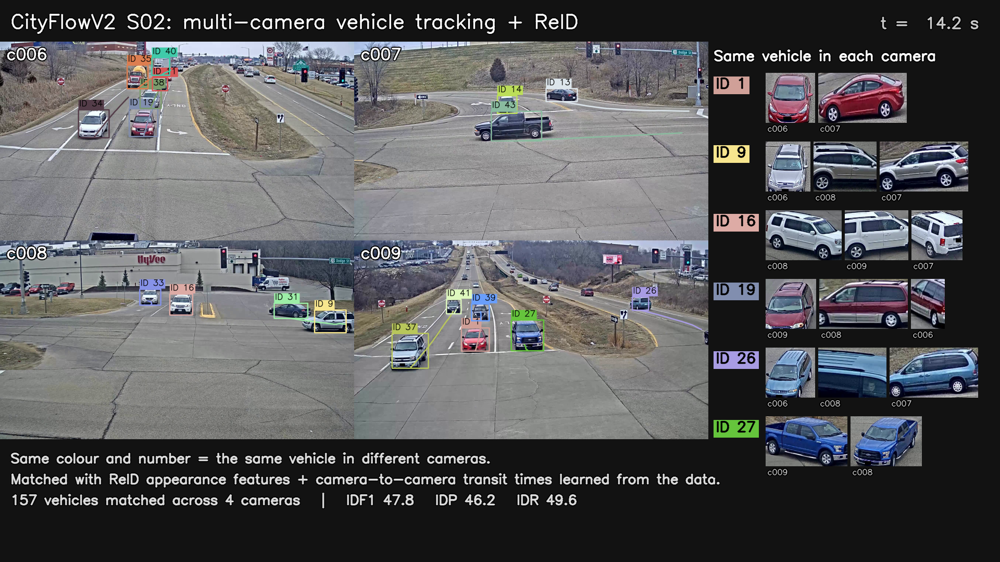

In [12]:
def colour(g):
    return tuple(int(v) for v in np.random.default_rng(g).integers(60, 256, 3))


def review_strips(sc: Scene, n):
    rev = sc.out / "review"
    shutil.rmtree(rev, ignore_errors=True)
    rev.mkdir()
    groups = defaultdict(list)
    for t in sc.all:
        if t.gid and t.crop is not None:
            groups[t.gid].append(t)
    order = sorted(groups, key=lambda g: (-len({t.cam for t in groups[g]}), g))[:n]
    for g in order:
        tiles = []
        for t in sorted(groups[g], key=lambda t: t.t0):
            c = cv2.resize(t.crop, (max(1, int(160 * t.crop.shape[1] / t.crop.shape[0])), 160))
            bar = np.full((22, max(c.shape[1], 150), 3), 20, np.uint8)
            cv2.putText(bar, f"{t.cam} {t.t0:.0f}-{t.t1:.0f}s", (4, 16), cv2.FONT_HERSHEY_SIMPLEX,
                        0.45, (230, 230, 230), 1, cv2.LINE_AA)
            c = cv2.copyMakeBorder(c, 0, 0, 0, bar.shape[1] - c.shape[1], cv2.BORDER_CONSTANT)
            tiles.append(cv2.copyMakeBorder(np.vstack([c, bar]), 0, 0, 0, 4, cv2.BORDER_CONSTANT))
        cv2.imwrite(str(rev / f"id{g:04d}.jpg"), np.hstack(tiles))
    return len(order)


def _text(img, text, org, scale, col, thick=1):
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, scale, (0, 0, 0), thick + 3, cv2.LINE_AA)
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, scale, col, thick, cv2.LINE_AA)


def _id_label(img, g, x, y, col, scale=1.1):
    txt = f"ID {g}"
    (w, h), base = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, scale, 2)
    y = max(y, h + base + 4)
    cv2.rectangle(img, (x, y - h - base - 4), (x + w + 8, y), col, -1)
    cv2.putText(img, txt, (x + 4, y - base - 2), cv2.FONT_HERSHEY_SIMPLEX, scale, (0, 0, 0), 2, cv2.LINE_AA)


def demo_clip(sc: Scene, path: Path, score_text="", seconds=DEMO_SECONDS, n_cams=DEMO_CAMS):
    W, H, TOP, PANEL = 1920, 1080, 80, 560
    groups = defaultdict(list)
    for t in sc.all:
        if t.gid:
            groups[t.gid].append(t)
    if not groups:
        print("no vehicle was matched across cameras, nothing to show")
        return None
    count = Counter(t.cam for t in sc.all if t.gid)
    cams = sorted(sorted(count, key=lambda c: -count[c])[:n_cams])
    boxes = {c: defaultdict(list) for c in cams}
    for t in sc.all:
        if t.gid and t.cam in boxes:
            for d in t.dets:
                if d["y2"] - d["y1"] >= PARAMS["min_h"]:      # same boxes as the submission
                    boxes[t.cam][d["frame"]].append((t.gid, d))

    # busiest window: most matched vehicles on screen, summed over the seconds
    t_lo = min(sc.cams[c].offset for c in cams)
    t_hi = max(sc.cams[c].offset + sc.cams[c].n_frames / sc.cams[c].fps for c in cams)
    per_sec = [set() for _ in range(int(t_hi - t_lo) + 1)]
    for c in cams:
        for f, lst in boxes[c].items():
            k = int(sc.cams[c].offset + (f - 1) / sc.cams[c].fps - t_lo)
            if 0 <= k < len(per_sec):
                per_sec[k].update(g for g, _ in lst)
    win = max(1, min(int(seconds), len(per_sec)))
    busy = [sum(len(x) for x in per_sec[s:s + win]) for s in range(len(per_sec) - win + 1)]
    t_start = t_lo + int(np.argmax(busy))

    # layout: camera grid on the left, vehicle panel on the right, caption below
    cols = 1 if len(cams) == 1 else 2
    rows = math.ceil(len(cams) / cols)
    tw = (W - PANEL) // cols
    th = tw * 9 // 16
    if rows * th > H - TOP - 150:
        th = (H - TOP - 150) // rows
        tw = th * 16 // 9
    grid_bottom = TOP + rows * th

    def vehicle_row(g):
        tiles = []
        for t in sorted(groups[g], key=lambda t: t.t0):
            if t.crop is None:
                continue
            w = min(170, max(1, int(96 * t.crop.shape[1] / t.crop.shape[0])))
            lab = np.full((22, w, 3), 18, np.uint8)
            _text(lab, t.cam, (3, 16), 0.5, (230, 230, 230))
            tiles.append(cv2.copyMakeBorder(np.vstack([cv2.resize(t.crop, (w, 96)), lab]),
                                            0, 0, 0, 6, cv2.BORDER_CONSTANT, value=(18, 18, 18)))
        row = np.full((118, PANEL - 20, 3), 18, np.uint8)
        _id_label(row, g, 0, 40, colour(g), 0.9)
        x = 100
        for tile in tiles:
            if x + tile.shape[1] > row.shape[1]:
                break
            row[:, x:x + tile.shape[1]] = tile
            x += tile.shape[1]
        return row

    row_cache = {}
    caption = ["Same colour and number = the same vehicle in different cameras.",
               "Matched with ReID appearance features + camera-to-camera transit times learned from the data.",
               f"{len(groups)} vehicles matched across {len(sc.cams)} cameras"
               + (f"   |   {score_text}" if score_text else "")]

    caps = {c: cv2.VideoCapture(str(sc.cams[c].video)) for c in cams}
    cur, img = {c: 0 for c in cams}, {c: None for c in cams}
    trail = defaultdict(list)
    tmp = path.with_name(path.stem + "_mp4v.mp4")
    vw = cv2.VideoWriter(str(tmp), cv2.VideoWriter_fourcc(*"mp4v"), 10, (W, H))
    poster, poster_n = None, -1
    for k in range(int(seconds * 10)):
        t = t_start + k / 10
        canvas = np.full((H, W, 3), 18, np.uint8)
        visible = Counter()
        for i, c in enumerate(cams):
            cam = sc.cams[c]
            f = int(round((t - cam.offset) * cam.fps)) + 1
            while cur[c] < f:
                ok = caps[c].grab() if cur[c] < f - 1 else None
                if cur[c] == f - 1:
                    ok, im = caps[c].read()
                    img[c] = im if ok else None
                cur[c] += 1
                if ok is False:
                    img[c] = None
            if f < 1 or img[c] is None:
                tile = np.zeros((th, tw, 3), np.uint8)
            else:
                p = img[c].copy()
                for g, d in boxes[c].get(f, ()):
                    col = colour(g)
                    visible[g] += 1
                    pts = trail[(c, g)]
                    pts.append((t, (d["x1"] + d["x2"]) / 2, d["y2"]))
                    while pts and t - pts[0][0] > DEMO_TRAIL:
                        pts.pop(0)
                    if len(pts) > 1:
                        cv2.polylines(p, [np.int32([(x, y) for _, x, y in pts])], False, col, 5, cv2.LINE_AA)
                    cv2.rectangle(p, (int(d["x1"]), int(d["y1"])), (int(d["x2"]), int(d["y2"])), col, 5)
                    _id_label(p, g, int(d["x1"]), int(d["y1"]) - 4, col, 1.5)
                tile = cv2.resize(p, (tw, th), interpolation=cv2.INTER_AREA)
            _text(tile, c, (12, 34), 1.0, (255, 255, 255), 2)
            x0, y0 = (i % cols) * tw, TOP + (i // cols) * th
            canvas[y0:y0 + th, x0:x0 + tw] = tile
        _text(canvas, f"CityFlowV2 {sc.name}: multi-camera vehicle tracking + ReID", (20, 54), 1.25,
              (255, 255, 255), 2)
        _text(canvas, f"t = {t - t_lo:5.1f} s", (W - PANEL + 330, 54), 1.0, (200, 200, 200), 2)
        for j, line in enumerate(caption):
            _text(canvas, line, (20, grid_bottom + 45 + 40 * j), 0.85, (220, 220, 220), 2)
        px, py = W - PANEL + 10, TOP + 10
        _text(canvas, "Same vehicle in each camera", (px, py + 26), 0.9, (255, 255, 255), 2)
        py += 50
        for g in sorted(visible, key=lambda g: (-len({t.cam for t in groups[g]}), g))[:DEMO_ROWS]:
            if g not in row_cache:
                row_cache[g] = vehicle_row(g)
            row = row_cache[g]
            if py + row.shape[0] > H:
                break
            canvas[py:py + row.shape[0], px:px + row.shape[1]] = row
            py += row.shape[0] + 14
        vw.write(canvas)
        if len(visible) > poster_n:
            poster, poster_n = canvas.copy(), len(visible)
    vw.release()
    for cap in caps.values():
        cap.release()
    cv2.imwrite(str(path.with_suffix(".png")), poster)
    if shutil.which("ffmpeg"):                       # H.264 for slides and browsers
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(tmp), "-c:v", "libx264",
                        "-pix_fmt", "yuv420p", "-crf", "23", "-movflags", "+faststart", str(path)],
                       check=False)
    if path.exists():
        tmp.unlink()
    else:
        tmp.replace(path)
    print(f"demo clip: {path} ({path.stat().st_size / 1e6:.1f} MB, {seconds} s from t = {t_start - t_lo:.0f} s, "
          f"cameras {', '.join(cams)});  still frame: {path.with_suffix('.png')}")
    return path


for sc in SC.values():
    print(f"{sc.name}: {review_strips(sc, N_REVIEW)} review strips in {sc.out / 'review'}")

demo_sc = SC[DEMO_SCENE or SCENES[0]]
txt = ""
if demo_sc.name in SCORES:
    f = SCORES[demo_sc.name][1]
    txt = f"IDF1 {100 * f[0]:.1f}   IDP {100 * f[1]:.1f}   IDR {100 * f[2]:.1f}"
demo = demo_clip(demo_sc, demo_sc.out / f"demo_{demo_sc.name}.mp4", txt)
if demo is not None:
    try:
        from IPython.display import Image as IPImage, Video, display
        display(IPImage(filename=str(demo.with_suffix(".png")), width=960))
        if demo.stat().st_size < 40e6:
            display(Video(str(demo), embed=True, width=960))
    except ImportError:
        pass

## Files written
* `out_<scene>/track1_<scene>.txt`: submission file per scene (the S06 one is the
  test-set submission for the evaluation server)
* `tuned_params.json`: the tuned settings (`TUNED_PARAMS` reuses them in a run without ground truth)
* `reid_*.pth`: ReID weights; attach them with `REID_WEIGHTS` to skip training
* `out_<scene>/tracks_yolo/c*.json`: cached single-camera tracks
* `out_<scene>/review/`, `out_<S02>/demo_S02.mp4` + `.png`: for checking matches and for slides